# Master Notebook — Prediksi Stunting Balita dengan XGBoost & LightGBM

Revisi eksperimen skripsi: **Baseline vs Class Weight vs SMOTE-NC vs SMOTE-NC + ENN**,
masing-masing pada XGBoost dan LightGBM (8 kombinasi).

Alur: loading → EDA → cleaning → empat fitur mentah dan encoding → split stratified 80:20
→ GridSearchCV dengan resampling di dalam training fold → evaluasi pada test set asli.
Semua skenario memperoleh grid yang sama per algoritma, 5 fold identik, dan scoring F1
kelas **Stunted = 1**, dengan `RANDOM_STATE = 42`.

**Audit metodologi master:** oversampling sebelum CV menyebabkan kebocoran informasi antar-fold;
baseline tanpa tuning membuat perbandingan tidak setara. Revisi memperbaiki kedua hal tersebut
dan memakai resampler yang mengenali Gender sebagai nominal. Kesimpulan dihasilkan dari eksekusi.
Snapshot membuktikan integritas data, sedangkan penempatan sampler dalam pipeline mencegah
kebocoran resampling antar-fold; snapshot saja tidak cukup membuktikan semua bentuk bebas leakage.

**Batasan yang dipertahankan:** cleaning Weight menggunakan asumsi pemulihan tanggal `day.month`;
validitas asumsi perlu didukung sumber data. Penghapusan baris karena `Weight for Height` kosong
tidak diperlukan untuk empat predictor, tetapi aturan master dipertahankan untuk konsistensi kohort.
EDA seluruh data dipertahankan sebagai deskripsi, tidak digunakan untuk memilih parameter.
Height, Age, dan Gender berkaitan langsung dengan pembentukan label antropometri: hasil ini adalah
klasifikasi status saat pengukuran, bukan bukti prediksi risiko stunting di masa depan.
Split baris tidak membuktikan independensi individu bila ada pengukuran berulang tanpa ID subjek.


# 1. Import Library & Loading Raw Data

Sel pertama berisi **seluruh import library** yang dipakai sepanjang notebook (dikelompokkan per
keperluan, tanpa duplikat), diikuti konstanta global dan *loading* data mentah.

- **Sumber data:** `data/raw/Overall Data.xlsx` (gabungan data survei 2021–2024).
- **Target:** kolom `Height for Age` (*Stunted* / *Not Stunted*).
- **Konvensi:** `RANDOM_STATE = 42` untuk reproducibility; kelas positif = `Stunted` (`POS_LABEL = 1`).

In [1]:
# ============================== IMPORT LIBRARY ==============================
# --- Manipulasi data & utilitas ---
import pandas as pd
import numpy as np
from datetime import datetime   # deteksi nilai Weight yang terbaca sebagai tanggal Excel
import time                     # pengukuran waktu tuning dan refit

# --- Visualisasi ---
import matplotlib.pyplot as plt
import seaborn as sns

# --- Splitting, tuning & metrik evaluasi (scikit-learn) ---
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    classification_report,
)

# --- Penanganan class imbalance (imbalanced-learn) ---
from imblearn.over_sampling import SMOTENC
from imblearn.under_sampling import EditedNearestNeighbours
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.model_selection import ParameterGrid
from joblib import Memory, parallel_config
from threadpoolctl import threadpool_limits
from pathlib import Path
from tempfile import TemporaryDirectory
from importlib.metadata import version
from IPython.display import display
import hashlib
import json
import sys

# --- Model ---
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

# --- Setup global ---
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)        # ukuran default figure (width, height)
pd.set_option("display.max_columns", None)      # tampilkan semua kolom dataframe

RANDOM_STATE = 42                               # seed seluruh proses stokastik
TEST_SIZE = 0.20                                # proporsi test set (split 80:20)
LABELS = ["Not Stunted", "Stunted"]             # urutan label kelas (0, 1)
POS_LABEL = 1                                   # kelas positif = Stunted
# Mendukung kernel yang dimulai dari root proyek atau folder notebooks.
PROJECT_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                     if (p / "data/raw/Overall Data.xlsx").is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Jalankan notebook dari folder proyek atau notebooks.")
DATA_PATH = PROJECT_ROOT / "data/raw/Overall Data.xlsx"
RUN_DIR = PROJECT_ROOT / "results/master_v2"
RUN_DIR.mkdir(parents=True, exist_ok=True)
GRID_N_JOBS = 4
MODEL_N_JOBS = 1
print("Python:", sys.version)
dependency_versions = {name: version(name) for name in [
    "pandas", "numpy", "scikit-learn", "imbalanced-learn", "xgboost",
    "lightgbm", "matplotlib", "seaborn", "openpyxl", "joblib"]}
print(dependency_versions)
print("SHA256 dataset:", hashlib.sha256(DATA_PATH.read_bytes()).hexdigest())

print("Semua library berhasil di-import. Konfigurasi global siap.")

Python: 3.14.3 (tags/v3.14.3:323c59a, Feb  3 2026, 16:04:56) [MSC v.1944 64 bit (AMD64)]
{'pandas': '3.0.5', 'numpy': '2.5.2', 'scikit-learn': None, 'imbalanced-learn': '0.14.2', 'xgboost': '3.4.1', 'lightgbm': '4.7.0', 'matplotlib': '3.11.1', 'seaborn': '0.13.2', 'openpyxl': '3.1.5', 'joblib': '1.5.3'}
SHA256 dataset: e6deda5fcae2695d79fb63bfd2508f57913fc4fbcc7eff792e8695e8ebd399e5
Semua library berhasil di-import. Konfigurasi global siap.


In [2]:
# Loading data mentah — satu-satunya pembacaan file di sepanjang notebook
df = pd.read_excel(DATA_PATH)
print(f"Shape data mentah: {df.shape[0]:,} baris x {df.shape[1]} kolom\n")
df.dtypes

Shape data mentah: 40,071 baris x 11 kolom



No.                    int64
Gender                   str
Age (Month)          float64
Weight                object
Height               float64
Weight for Age           str
Z-Score  W/A          object
Height for Age           str
Z-Score H/A           object
Weight for Height        str
Z-Score W/H           object
dtype: object

In [3]:
# Preview 5 baris pertama
df.head()

,No.,Gender,Age (Month),Weight,Height,Weight for Age,Z-Score W/A,Height for Age,Z-Score H/A,Weight for Height,Z-Score W/H
0,1,F,54.0,13.2,97.5,Normal,-1.94,Stunted,-2.11,Normal,-0.95
1,2,M,44.0,12,92.0,Normal,-1.92,Stunted,-2.22,Normal,-0.88
2,3,M,57.0,14,97.0,Normal,-1.9,Stunted,-2.58,Normal,-0.48
3,4,M,26.0,11,79.0,Normal,-1.15,Stunted,-3.11,Normal,0.68
4,5,F,59.0,14.6,98.0,Normal,-1.66,Stunted,-2.49,Normal,-0.18


> **Temuan awal penting:** kolom `Weight` terbaca bercampur tipe data (`datetime`/`int`/`str`)
> akibat *auto-conversion* Excel — sebagian nilai desimal (mis. `8.2`) terubah menjadi tanggal
> (`2025-02-08`). Inspeksi detail dilakukan pada Bagian 2 (EDA) dan perbaikannya pada Bagian 3.

# 2. Exploratory Data Analysis (EDA)

Analisis eksplorasi awal dataset stunting balita. Bagian ini **hanya eksplorasi** dan tidak
melakukan perubahan data apa pun.

Target penelitian: kolom `Height for Age` (*Stunted* / *Not Stunted*).
Fitur mentah (variabel independen): `Gender`, `Age (Month)`, `Weight`, `Height`.

Fokus pemeriksaan: kelengkapan data (missing value, duplikat, konsistensi kategori), distribusi
target & fitur, indikasi outlier, hubungan fitur dengan target, serta data-quality kolom `Weight`.

## 2.1 Missing Value per Kolom

In [4]:
# Hitung missing value per kolom (hanya tampilkan kolom yang memiliki missing)
missing = df.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
if len(missing) == 0:
    print("Tidak ada missing value di kolom mana pun.")
else:
    print("Kolom dengan missing value:")
    print(missing)

Kolom dengan missing value:
Weight for Height    5
Age (Month)          2
dtype: int64


## 2.2 Cek Duplikat Baris

In [5]:
# Duplikat baris penuh (semua kolom identik)
n_duplicates = df.duplicated().sum()
print(f"Jumlah baris duplikat: {n_duplicates}")

Jumlah baris duplikat: 0


## 2.3 Nilai Unik & Konsistensi Kategori

Memeriksa nilai unik pada kolom kategorikal untuk mendeteksi kemungkinan inkonsistensi label
(spasi berlebih, kapitalisasi, atau variasi penulisan) yang dapat memengaruhi hasil encoding
pada tahap preprocessing.

In [6]:
# Nilai unik tiap kolom kategorikal
cat_cols = ["Gender", "Height for Age", "Weight for Age", "Weight for Height"]
for col in cat_cols:
    uniq = df[col].dropna().unique()
    print(f"{col} ({len(uniq)} unik): {uniq}\n")

Gender (2 unik): <StringArray>
['F', 'M']
Length: 2, dtype: str

Height for Age (2 unik): <StringArray>
['Stunted', 'Not Stunted']
Length: 2, dtype: str

Weight for Age (4 unik): <StringArray>
['Normal', 'Underfed', 'Malnutrition', 'Overnutrition']
Length: 4, dtype: str

Weight for Height (4 unik): <StringArray>
['Normal', 'Thin', 'Obese', 'Very Thin']
Length: 4, dtype: str



## 2.4 Distribusi Kelas Target (`Height for Age`)

In [7]:
# Tabel distribusi kelas target (jumlah & persentase)
target_counts = df["Height for Age"].value_counts(dropna=False)
target_pct = df["Height for Age"].value_counts(dropna=False, normalize=True) * 100
target_dist = pd.DataFrame({"count": target_counts, "percentage": target_pct.round(2)})
target_dist

,count,percentage
Height for Age,,
Not Stunted,23867,59.56
Stunted,16204,40.44


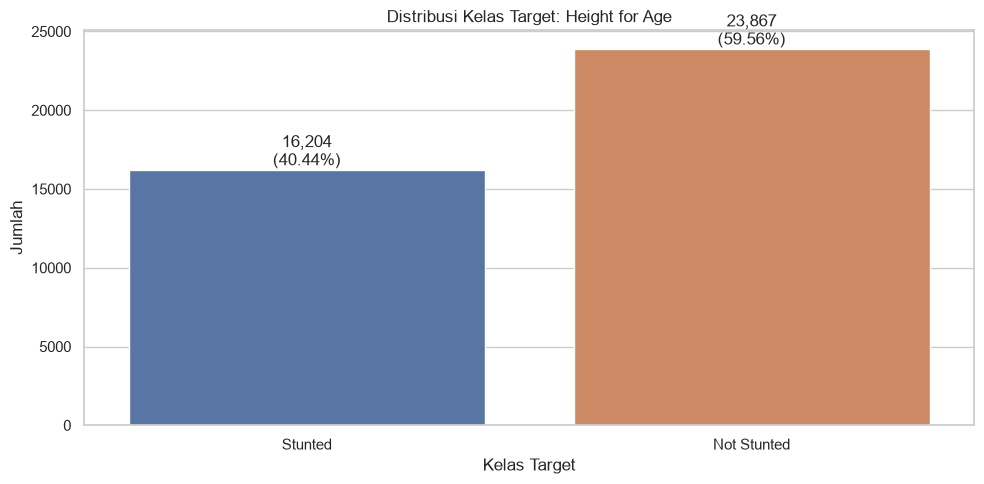

In [8]:
# Visualisasi distribusi kelas target dengan anotasi jumlah & persentase
ax = sns.countplot(data=df, x="Height for Age", hue="Height for Age", legend=False)
ax.set_title("Distribusi Kelas Target: Height for Age")
ax.set_xlabel("Kelas Target")
ax.set_ylabel("Jumlah")
for p in ax.patches:
    ax.annotate(f"{int(p.get_height()):,}\n({p.get_height()/len(df)*100:.2f}%)",
                (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
plt.tight_layout()
plt.show()

### Catatan: Keseimbangan Kelas

Distribusi target menunjukkan mild imbalance. Manfaat Class Weight, SMOTE-NC,
dan SMOTE-NC + ENN harus diuji terhadap Baseline dengan prosedur tuning setara;
penanganan imbalance tidak diasumsikan selalu meningkatkan performa.

## 2.5 Visualisasi Distribusi Fitur Mentah

Fitur: `Gender` (kategorikal), `Age (Month)` & `Height` (numerik). `Weight` **tidak
divisualisasikan** karena masih korup (campuran tipe data) — dibahas khusus pada sub-bagian 2.9.

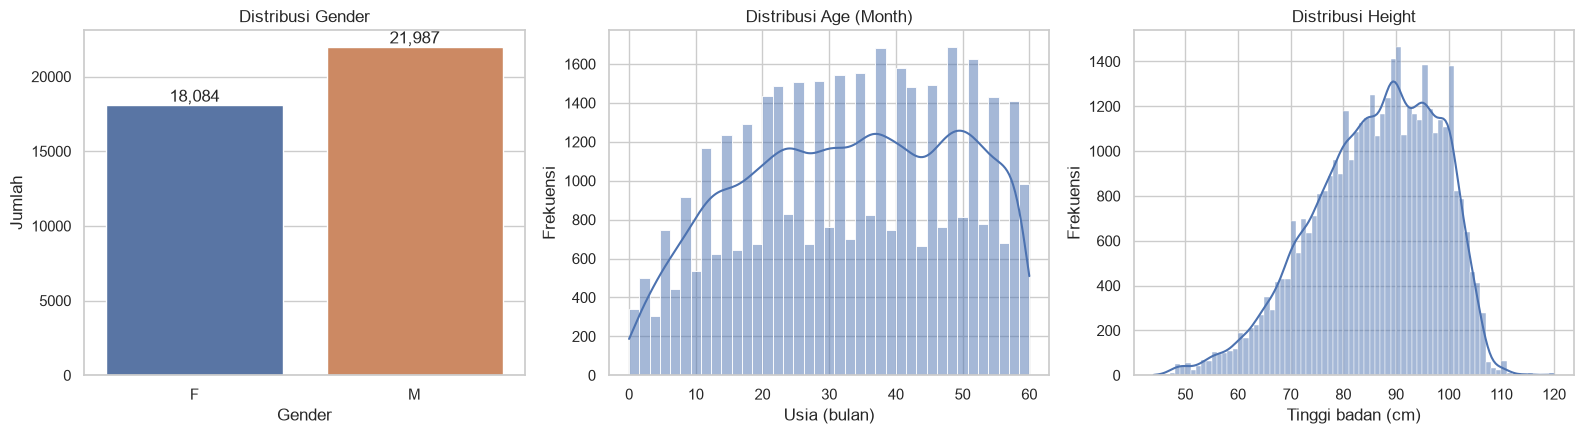

In [9]:
# Grid 1x3: distribusi Gender (countplot), Age & Height (histplot + KDE)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

sns.countplot(data=df, x="Gender", hue="Gender", legend=False, ax=axes[0])
axes[0].set_title("Distribusi Gender")
axes[0].set_xlabel("Gender")
axes[0].set_ylabel("Jumlah")
for p in axes[0].patches:
    axes[0].annotate(f"{int(p.get_height()):,}",
                     (p.get_x() + p.get_width() / 2, p.get_height()),
                     ha="center", va="bottom")

sns.histplot(df["Age (Month)"].dropna(), kde=True, ax=axes[1])
axes[1].set_title("Distribusi Age (Month)")
axes[1].set_xlabel("Usia (bulan)")
axes[1].set_ylabel("Frekuensi")

sns.histplot(df["Height"].dropna(), kde=True, ax=axes[2])
axes[2].set_title("Distribusi Height")
axes[2].set_xlabel("Tinggi badan (cm)")
axes[2].set_ylabel("Frekuensi")

plt.tight_layout()
plt.show()

## 2.6 Statistik Deskriptif Fitur Numerik

Ringkasan statistik `Age (Month)` dan `Height`. Kolom `Weight` sengaja dikecualikan karena masih
korup pada data mentah; statistiknya baru sahih setelah perbaikan pada Bagian 3.

In [10]:
# Statistik deskriptif fitur numerik yang valid
df[["Age (Month)", "Height"]].describe().T

,count,mean,std,min,25%,50%,75%,max
Age (Month),40069.0,33.020664,15.823079,0.0,20.0,34.0,47.0,60.0
Height,40071.0,86.051172,11.816466,44.0,78.0,87.3,95.2,120.0


## 2.7 Eksplorasi Outlier (Age & Height)

Boxplot untuk mendeteksi nilai ekstrem. EDA di sini **hanya mendeteksi**, bukan menghapus;
keputusan penanganan outlier ditunda ke tahap *cleaning* (Bagian 3). `Weight` dikecualikan karena
masih korup pada data mentah.

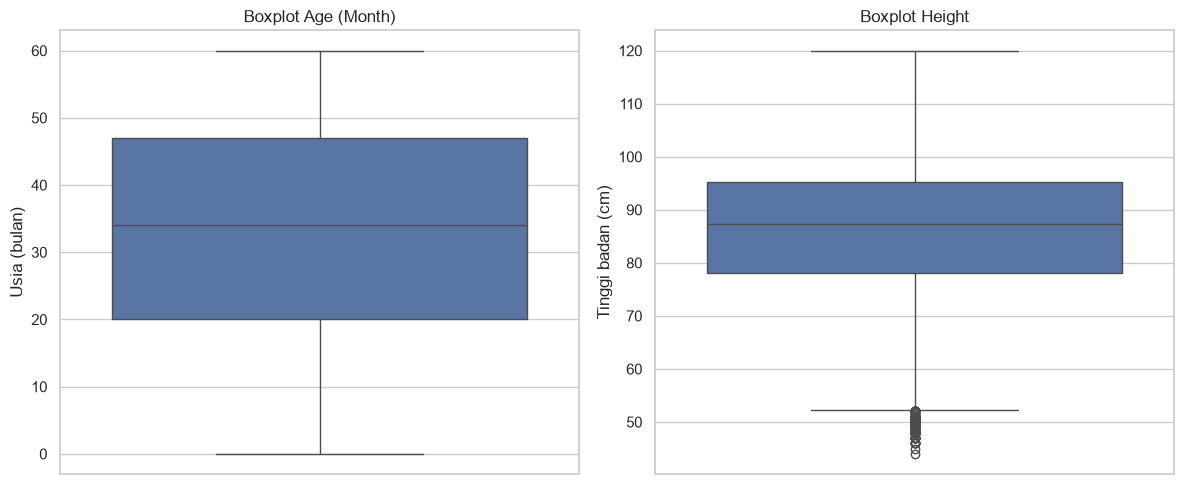

In [11]:
# Boxplot Age & Height untuk deteksi outlier awal
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(data=df, y="Age (Month)", ax=axes[0])
axes[0].set_title("Boxplot Age (Month)")
axes[0].set_ylabel("Usia (bulan)")

sns.boxplot(data=df, y="Height", ax=axes[1])
axes[1].set_title("Boxplot Height")
axes[1].set_ylabel("Tinggi badan (cm)")

plt.tight_layout()
plt.show()

## 2.8 Hubungan Fitur dengan Target (`Height for Age`)

Melihat apakah fitur mentah mampu membedakan kelas *Stunted* vs *Not Stunted*. `Weight`
dikecualikan (masih korup); fokus pada `Age (Month)`, `Height`, dan `Gender`.

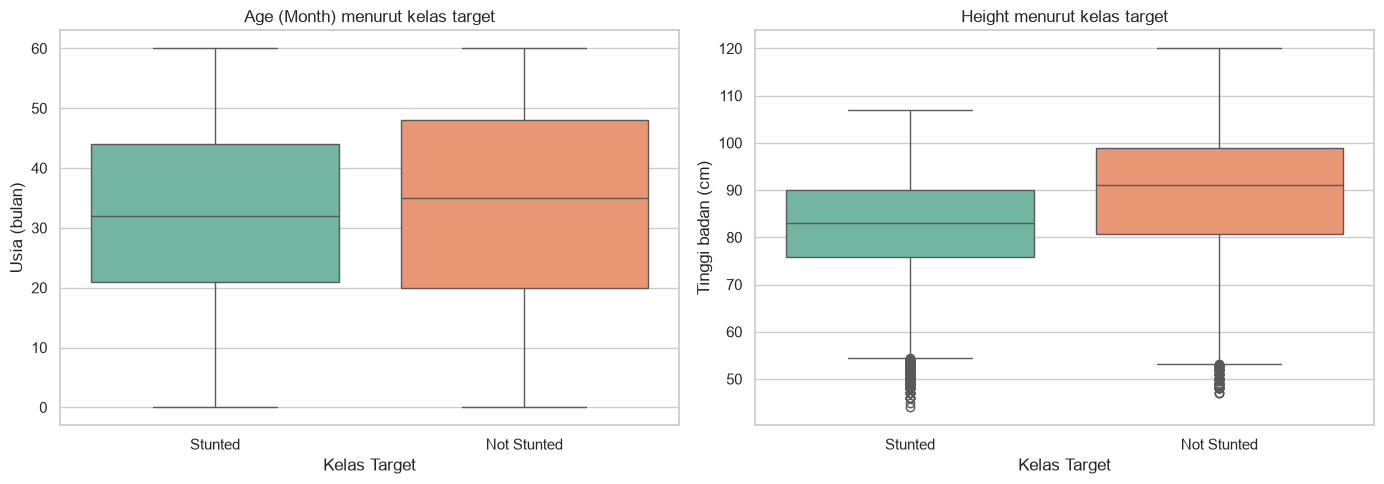

In [12]:
# Boxplot Age & Height menurut kelas target (indikasi daya pisah fitur)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=df, x="Height for Age", y="Age (Month)", hue="Height for Age",
            legend=False, palette="Set2", ax=axes[0])
axes[0].set_title("Age (Month) menurut kelas target")
axes[0].set_xlabel("Kelas Target")
axes[0].set_ylabel("Usia (bulan)")

sns.boxplot(data=df, x="Height for Age", y="Height", hue="Height for Age",
            legend=False, palette="Set2", ax=axes[1])
axes[1].set_title("Height menurut kelas target")
axes[1].set_xlabel("Kelas Target")
axes[1].set_ylabel("Tinggi badan (cm)")

plt.tight_layout()
plt.show()

In [13]:
# Statistik Age & Height per kelas target
df.groupby("Height for Age")[["Age (Month)", "Height"]].agg(["count", "mean", "median", "std"])

Age (Month)                              Height             \
                     count       mean median        std  count       mean   
Height for Age                                                              
Not Stunted          23865  33.651372   35.0  16.501899  23867  88.720644   
Stunted              16204  32.091767   32.0  14.717976  16204  82.119285   

                                  
               median        std  
Height for Age                    
Not Stunted      91.0  12.135873  
Stunted          83.0  10.119848

### Gender × Target

Crosstab jumlah dan persentase (*row-normalized*) untuk melihat apakah proporsi stunting
berbeda menurut gender.

In [14]:
# Crosstab Gender × Target: jumlah absolut dan persentase per baris
display(pd.crosstab(df["Gender"], df["Height for Age"], margins=True))
display(pd.crosstab(df["Gender"], df["Height for Age"], normalize="index").mul(100).round(2))

Height for Age,Not Stunted,Stunted,All
Gender,,,
F,11207,6877,18084
M,12660,9327,21987
All,23867,16204,40071


Height for Age,Not Stunted,Stunted
Gender,,
F,61.97,38.03
M,57.58,42.42


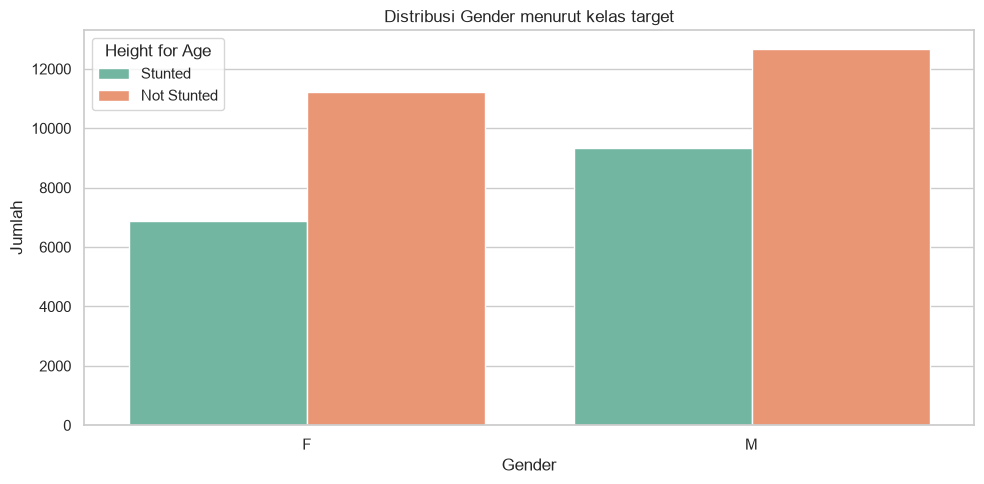

In [15]:
# Visualisasi proporsi kelas target menurut gender
ax = sns.countplot(data=df, x="Gender", hue="Height for Age", palette="Set2")
ax.set_title("Distribusi Gender menurut kelas target")
ax.set_xlabel("Gender")
ax.set_ylabel("Jumlah")
plt.tight_layout()
plt.show()

## 2.9 Inspeksi Data-Quality Kolom `Weight`

Kolom `Weight` dicurigai rusak akibat *auto-conversion* Excel: sebagian nilai numerik
(misalnya `8.2`) terbaca sebagai tanggal `datetime`. Berikut diperiksa **tipe data tiap nilai**
di kolom ini (int / str / datetime) tanpa melakukan perbaikan.

In [16]:
# Distribusi tipe data per nilai pada kolom Weight
weight_dtype_counts = df["Weight"].map(type).value_counts()
print("Distribusi tipe data per nilai pada kolom Weight:")
print(weight_dtype_counts)

# Rincian jumlah & persentase tiap tipe
is_datetime = df["Weight"].map(lambda x: isinstance(x, datetime))
is_int = df["Weight"].map(lambda x: isinstance(x, int))
is_str = df["Weight"].map(lambda x: isinstance(x, str))
print(f"\nTotal nilai Weight: {len(df):,}")
print(f"  - datetime: {is_datetime.sum():,} ({is_datetime.sum()/len(df)*100:.2f}%)")
print(f"  - int     : {is_int.sum():,} ({is_int.sum()/len(df)*100:.2f}%)")
print(f"  - str     : {is_str.sum():,} ({is_str.sum()/len(df)*100:.2f}%)")

Distribusi tipe data per nilai pada kolom Weight:
Weight
<class 'datetime.datetime'>    20158
<class 'int'>                  10780
<class 'str'>                   9133
Name: count, dtype: int64

Total nilai Weight: 40,071
  - datetime: 20,158 (50.31%)
  - int     : 10,780 (26.90%)
  - str     : 9,133 (22.79%)


In [17]:
# Contoh nilai Weight yang terbaca sebagai datetime & sebagai string
print("Contoh nilai Weight yang terbaca sebagai datetime:")
display(df.loc[is_datetime, "Weight"].head(10))
print("Contoh nilai Weight yang terbaca sebagai string:")
display(df.loc[is_str, "Weight"].head(10))

Contoh nilai Weight yang terbaca sebagai datetime:


12300    2025-02-08 00:00:00
12301    2025-07-14 00:00:00
12303    2025-05-12 00:00:00
12304    2025-04-10 00:00:00
12306    2025-06-16 00:00:00
12310    2025-02-13 00:00:00
12312    2025-04-15 00:00:00
12313    2025-09-13 00:00:00
12314    2025-05-15 00:00:00
12315    2025-08-14 00:00:00
Name: Weight, dtype: object

Contoh nilai Weight yang terbaca sebagai string:


0     13.2
4     14.6
8     14.2
10    11.5
11    13.1
13    11.1
14    11.1
16     9.5
17    14.7
18    11.2
Name: Weight, dtype: object

## 2.10 Ringkasan Temuan EDA

1. Dataset **40.071 baris × 11 kolom**, tanpa duplikat.
2. Missing value minor: `Age (Month)` (2 nilai) dan `Weight for Height` (5 nilai).
3. Target `Height for Age` relatif seimbang: *Not Stunted* 59.56% vs *Stunted* 40.44%.
4. Kolom `Weight` **korup** (≈ 50% terbaca *datetime* akibat *auto-conversion* Excel).
5. Dari boxplot, `Height` dan `Age` tampak berbeda antara *Stunted*/*Not Stunted* — indikasi awal
   kedua fitur tersebut informatif.
6. Kolom turunan (`Weight for Age`, `Z-Score`, dll.) berpotensi *data leakage* dan akan dibuang
   pada tahap preprocessing (Bagian 4).

# 3. Data Cleaning & Outlier Handling (Perbaikan Kolom Weight dan Penanganan Missing Values)

Bagian ini membersihkan data mentah menjadi data siap-pakai secara **langsung di memori**
(`df` → `df_clean`), tanpa menyimpan/memuat file perantara. Tahapan:

1. **Perbaikan kolom `Weight`** — kerusakan akibat *auto-conversion* Excel (datetime → desimal).
2. **Penanganan outlier `Weight`** — koreksi nilai skala gram & penghapusan nilai mustahil.
3. **Penanganan missing value** pada `Age (Month)` dan `Weight for Height`.
4. **Validasi akhir** — memastikan data bersih sepenuhnya sebelum masuk preprocessing.

> Catatan: `df` (data mentah) sengaja dibiarkan utuh sebagai pembanding *before/after*.

## 3.1 Perbaikan Kolom `Weight`

Kolom `Weight` tercampur 3 tipe data akibat *auto-conversion* Excel:

- `datetime` → nilai desimal asli (misal `2025-02-08` → `8.2`, yaitu format `day.month`,
  umum di *locale* Indonesia/Eropa),
- `int` / `float` / `str` numerik → dikonversi ke `float`.

Aturan konversi datetime: `float(f"{day}.{month}")`.

In [18]:
print("Sebelum perbaikan — tipe data per nilai pada kolom Weight:")
print(df["Weight"].map(type).value_counts())

# Fungsi konversi nilai Weight campuran tipe menjadi float (kg)
def fix_weight_value(x):
    if isinstance(x, datetime):            # tanggal Excel → desimal asli (format day.month)
        return float(f"{x.day}.{x.month}")
    if isinstance(x, bool):
        return float(x)
    if isinstance(x, (int, float)):        # numerik → float
        return float(x)
    if isinstance(x, str):                 # string numerik → float
        return float(x.strip())
    return np.nan                          # tipe tak dikenali → NaN

# Terapkan perbaikan pada salinan data (df mentah tetap utuh sebagai pembanding)
df_clean = df.copy()
df_clean["Weight"] = df_clean["Weight"].apply(fix_weight_value)
print("\nDtype Weight setelah konversi:", df_clean["Weight"].dtype)
print("Jumlah NaN baru pada Weight:", df_clean["Weight"].isna().sum())

Sebelum perbaikan — tipe data per nilai pada kolom Weight:
Weight
<class 'datetime.datetime'>    20158
<class 'int'>                  10780
<class 'str'>                   9133
Name: count, dtype: int64

Dtype Weight setelah konversi: float64
Jumlah NaN baru pada Weight: 0


## 3.2 Validasi Rentang Weight (1–30 kg)

Setelah konversi, cek apakah semua nilai berada pada rentang wajar berat badan balita (±1–30 kg).

In [19]:
# Deteksi nilai Weight di luar rentang wajar balita
low_mask = df_clean["Weight"] < 1
high_mask = df_clean["Weight"] > 30
print(f"Weight < 1 kg : {low_mask.sum()}")
print(f"Weight > 30 kg: {high_mask.sum()}")
print("Nilai Weight > 30 kg:", sorted(df_clean.loc[high_mask, "Weight"].unique()))

Weight < 1 kg : 0
Weight > 30 kg: 6
Nilai Weight > 30 kg: [np.float64(91.0), np.float64(2800.0), np.float64(2900.0), np.float64(3000.0), np.float64(3085.0), np.float64(3100.0)]


### Penanganan Outlier Weight

Validasi menemukan dua jenis nilai di luar rentang wajar:

1. **Nilai skala gram** (`2800, 2900, 3000, 3085, 3100`) — berat bayi baru lahir yang tercatat
   dalam satuan **gram** (2,8–3,1 kg adalah berat lahir normal). Perbaikan: **bagi 1000**.
2. **Nilai `91`** — mustahil secara biologis untuk balita dan nilai aslinya tidak dapat
   dipastikan. Karena hanya 1 baris, baris ini **dihapus** (*drop*) daripada ditebak.

In [20]:
# Koreksi nilai skala gram → kg (dibagi 1000)
gram_mask = df_clean["Weight"] >= 1000
n_gram = gram_mask.sum()
df_clean.loc[gram_mask, "Weight"] = df_clean.loc[gram_mask, "Weight"] / 1000
print(f"Nilai skala gram yang dikoreksi (dibagi 1000): {n_gram}")
print("Nilai setelah koreksi:", df_clean.loc[gram_mask, "Weight"].tolist())

Nilai skala gram yang dikoreksi (dibagi 1000): 5
Nilai setelah koreksi: [3.085, 3.1, 2.9, 3.0, 2.8]


In [21]:
# Drop baris dengan Weight di luar rentang wajar (mustahil secara biologis)
implausible_mask = (df_clean["Weight"] < 1) | (df_clean["Weight"] > 30)
print("Baris dengan Weight di luar 1–30 kg (akan di-drop):", implausible_mask.sum())
display(df_clean.loc[implausible_mask, ["No.", "Gender", "Age (Month)", "Weight", "Height", "Weight for Height"]])

df_clean = df_clean.loc[~implausible_mask].reset_index(drop=True)
print("Shape setelah drop outlier Weight:", df_clean.shape)

Baris dengan Weight di luar 1–30 kg (akan di-drop): 1


,No.,Gender,Age (Month),Weight,Height,Weight for Height
26336,26337,F,28.0,91.0,84.0,NaN


Shape setelah drop outlier Weight: (40070, 11)


## 3.3 Penanganan Missing Value

**Strategi: drop baris** (bukan imputasi).

- **`Age (Month)`** — 2 nilai hilang (0,005% dari 40.071). Usia adalah fitur numerik kunci;
  imputasi median/mean akan menyuntikkan nilai sintetis yang tidak berasal dari pengukuran,
  sedangkan *drop* hanya kehilangan data yang dapat diabaikan → **drop**.
- **`Weight for Height`** — 5 nilai hilang. Kolom ini adalah **fitur turunan** yang sesuai
  metodologi justru akan dibuang saat feature selection (anti-leakage, Bagian 4), sehingga
  imputasi tidak memberi manfaat apa pun bagi pemodelan → **drop**.

In [22]:
print("Missing value sebelum drop:")
print(df_clean[["Age (Month)", "Weight for Height"]].isna().sum())

# Drop baris yang memiliki missing pada Age (Month) atau Weight for Height
missing_mask = df_clean["Age (Month)"].isna() | df_clean["Weight for Height"].isna()
n_dropped_missing = missing_mask.sum()
df_clean = df_clean.loc[~missing_mask].reset_index(drop=True)
print(f"\nBaris di-drop karena missing value: {n_dropped_missing}")
print("Shape setelah drop missing value:", df_clean.shape)

Missing value sebelum drop:
Age (Month)          2
Weight for Height    4
dtype: int64

Baris di-drop karena missing value: 6
Shape setelah drop missing value: (40064, 11)


## 3.4 Validasi Akhir Data Bersih

Memastikan tidak ada missing value tersisa dan seluruh `Weight` berada pada rentang wajar (1–30 kg).

In [23]:
# Validasi akhir: data bersih total sebelum masuk preprocessing
print("Missing value total tersisa:", int(df_clean.isna().sum().sum()))
print("Rentang Weight akhir:", df_clean["Weight"].min(), "-", df_clean["Weight"].max(), "kg")
print("Weight di luar 1–30 kg:", int(((df_clean["Weight"] < 1) | (df_clean["Weight"] > 30)).sum()))
print("Dtype Weight akhir:", df_clean["Weight"].dtype)
print("Dtype Age (Month) akhir:", df_clean["Age (Month)"].dtype)

Missing value total tersisa: 0
Rentang Weight akhir: 2.0 - 28.5 kg
Weight di luar 1–30 kg: 0
Dtype Weight akhir: float64
Dtype Age (Month) akhir: float64


## 3.5 Ringkasan Before / After Cleaning

In [24]:
# Perbandingan before/after — df (mentah, utuh) vs df_clean (tanpa baca ulang file)
summary = pd.DataFrame({
    "Aspek": [
        "Jumlah baris",
        "Jumlah kolom",
        "Missing Age (Month)",
        "Missing Weight for Height",
        "Tipe campuran kolom Weight",
        "Dtype Weight",
        "Rentang Weight (kg)",
    ],
    "Before": [
        len(df),
        df.shape[1],
        int(df["Age (Month)"].isna().sum()),
        int(df["Weight for Height"].isna().sum()),
        "datetime/int/str",
        str(df["Weight"].dtype),
        "tidak valid (datetime, gram, outlier)",
    ],
    "After": [
        len(df_clean),
        df_clean.shape[1],
        int(df_clean["Age (Month)"].isna().sum()),
        int(df_clean["Weight for Height"].isna().sum()),
        "seragam (numerik)",
        str(df_clean["Weight"].dtype),
        f"{df_clean['Weight'].min():.2f} - {df_clean['Weight'].max():.2f}",
    ],
})
summary

,Aspek,Before,After
0,Jumlah baris,40071,40064
1,Jumlah kolom,11,11
2,Missing Age (Month),2,0
3,Missing Weight for Height,5,0
4,Tipe campuran kolom Weight,datetime/int/str,seragam (numerik)
5,Dtype Weight,object,float64
6,Rentang Weight (kg),"tidak valid (datetime, gram, outlier)",2.00 - 28.50


In [25]:
# Distribusi kelas target setelah cleaning (proporsi harus tetap ±60:40)
print("Distribusi kelas target setelah cleaning:")
vc = df_clean["Height for Age"].value_counts()
print(vc)
print((vc / len(df_clean) * 100).round(2))

Distribusi kelas target setelah cleaning:
Height for Age
Not Stunted    23864
Stunted        16200
Name: count, dtype: int64
Height for Age
Not Stunted    59.56
Stunted        40.44
Name: count, dtype: float64


# 4. Preprocessing & Data Splitting
## 4.1 Feature Selection dan Pencegahan Data Leakage
Gunakan hanya Gender, Age (Month), Weight, dan Height. Target serta seluruh kolom turunan
dan No. tidak dimasukkan sebagai predictor. Tidak ada seleksi fitur berdasarkan skor test.

In [26]:
TARGET_COL = "Height for Age"
FEATURES = ["Gender", "Age (Month)", "Weight", "Height"]
FORBIDDEN = {"Weight for Age", "Z-Score W/A", "Z-Score H/A",
             "Weight for Height", "Z-Score W/H", "No.", TARGET_COL}
assert not FORBIDDEN.intersection(" ".join(c.split()) for c in FEATURES)
X = df_clean.loc[:, FEATURES].copy()
assert list(X.columns) == FEATURES
print("Predictor:", X.columns.tolist())

Predictor: ['Gender', 'Age (Month)', 'Weight', 'Height']


## 4.2 Encoding Fitur Kategorikal dan Target
Mapping deterministik: M → 0, F → 1; Not Stunted → 0, Stunted → 1.
Encoding tidak dipelajari dari test. Age (Month), Weight, dan Height tetap numerik kontinu.
Skala asli master dipertahankan. Ini perlu dicatat karena metode berbasis tetangga sensitif
terhadap skala; kode Gender 0/1 tetap ditandai nominal pada SMOTE-NC.

In [27]:
X["Gender"] = X["Gender"].map({"M": 0, "F": 1})
y = df_clean[TARGET_COL].map({"Not Stunted": 0, "Stunted": 1})
assert not X.isna().any().any(), "Ada missing/kategori Gender tidak dikenal."
assert not y.isna().any(), "Ada target tidak dikenal."
assert set(X["Gender"].unique()) == {0, 1}
assert set(y.unique()) == {0, 1}
assert all(pd.api.types.is_numeric_dtype(X[c]) for c in FEATURES)
assert np.isfinite(X.to_numpy(dtype=float)).all()
display(X.dtypes)
display(y.value_counts().sort_index())

Gender           int64
Age (Month)    float64
Weight         float64
Height         float64
dtype: object

Height for Age
0    23864
1    16200
Name: count, dtype: int64

## 4.3 Train-Test Split 80:20 Stratified
Split dilakukan sekali, sebelum resampling. Snapshot training dan test disimpan;
ukuran test diturunkan dari split, tidak di-hard-code.

In [28]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE)
X_train_snapshot = X_train.copy(deep=True)
y_train_snapshot = y_train.copy(deep=True)
X_test_snapshot = X_test.copy(deep=True)
y_test_snapshot = y_test.copy(deep=True)
n_test_original = len(X_test)
categorical_indices = [X_train.columns.get_loc("Gender")]
assert categorical_indices == [0]
assert X_train.index.intersection(X_test.index).empty
assert X_train.index.equals(y_train.index) and X_test.index.equals(y_test.index)
print("Training:", X_train.shape, "Test:", X_test.shape)
print("Categorical indices:", categorical_indices)

Training: (32051, 4) Test: (8013, 4)
Categorical indices: [0]


## 4.4 Distribusi Kelas Training dan Test
Distribusi test tetap berasal dari kohort setelah cleaning, tanpa penyeimbangan kelas.

In [29]:
# Helper cetak distribusi kelas (dipakai ulang di Bagian 6)
def show_dist(name, target):
    s = pd.Series(target)
    counts = s.value_counts().sort_index()
    pct = (s.value_counts(normalize=True).sort_index() * 100).round(2)
    print(f"{name} (total {len(s):,}):")
    for cls in [0, 1]:
        label = "Not Stunted" if cls == 0 else "Stunted"
        print(f"    {label} ({cls}): {counts.get(cls, 0):,}  ({pct.get(cls, 0):.2f}%)")
    print()

show_dist("y (full)", y)
show_dist("y_train", y_train)
show_dist("y_test", y_test)

y (full) (total 40,064):
    Not Stunted (0): 23,864  (59.56%)
    Stunted (1): 16,200  (40.44%)

y_train (total 32,051):
    Not Stunted (0): 19,091  (59.56%)
    Stunted (1): 12,960  (40.44%)

y_test (total 8,013):
    Not Stunted (0): 4,773  (59.57%)
    Stunted (1): 3,240  (40.43%)



## 4.5 Perhitungan scale_pos_weight
Bobot XGBoost dihitung hanya dari y_train asli, kemudian ditetapkan untuk seluruh kandidat
dan fold sesuai protokol penelitian. Tidak dituning dan tidak dihitung dari y_test.
Nilai > 1 memperbesar bobot loss kelas Stunted; pada mild imbalance nilainya umumnya tidak besar.
LightGBM menggunakan `is_unbalance=True` pada skenario Class Weight.

In [30]:
negative_count = int((y_train == 0).sum())
positive_count = int((y_train == 1).sum())
assert negative_count > 0 and positive_count > 0
scale_pos_weight = negative_count / positive_count
print("negative_count (Not Stunted):", negative_count)
print("positive_count (Stunted):", positive_count)
print("scale_pos_weight:", scale_pos_weight)

negative_count (Not Stunted): 19091
positive_count (Stunted): 12960
scale_pos_weight: 1.473070987654321


## 4.6 Validasi Anti-Data-Leakage
Helper berikut dipanggil setelah demonstrasi, setelah setiap GridSearchCV, dan sebelum evaluasi.
Training asli juga tidak boleh ditimpa. Pemeriksaan indeks menjamin pemisahan baris.

In [31]:
def assert_original_data():
    assert X_test.equals(X_test_snapshot), "X_test berubah!"
    assert y_test.equals(y_test_snapshot), "y_test berubah!"
    assert len(X_test) == len(y_test) == n_test_original
    assert X_train.equals(X_train_snapshot), "X_train asli berubah!"
    assert y_train.equals(y_train_snapshot), "y_train asli berubah!"
    assert list(X_train.columns) == list(X_test.columns) == FEATURES
    assert X_train.index.intersection(X_test.index).empty

assert_original_data()
print("Integritas training dan test tervalidasi.")

Integritas training dan test tervalidasi.


# 5. Definisi Skenario Eksperimen
## 5.1 Baseline
Tanpa resampling dan class weight: XGBoost `scale_pos_weight=1`, LightGBM
`is_unbalance=False`, `class_weight=None`. Baseline tetap memperoleh tuning penuh.
## 5.2 Built-in Class Weight
Tanpa resampling. XGBoost memakai rasio y_train; LightGBM memakai `is_unbalance=True`.
Tidak memberikan `scale_pos_weight` pada LightGBM sehingga tidak terjadi kombinasi bobot.
## 5.3 SMOTE-NC
SMOTENC dengan Gender kategorikal, k=5, sampling_strategy='auto', random_state=42.
Tanpa class weighting.
## 5.4 SMOTE-NC + ENN
Urutan eksplisit SMOTENC → EditedNearestNeighbours(n_neighbors=3) → classifier.
Tanpa class weighting. ENN memakai default `sampling_strategy='auto'` (kelas selain minoritas)
dan `kind_sel='all'`; ketika kelas sama banyak, pemilihan kelas mengikuti aturan library.
ENN bukan metrik khusus data campuran dan memakai jarak pada Gender 0/1 serta numerik skala asli.
Ini merupakan keterbatasan yang perlu dibedakan dari perlakuan nominal Gender dalam SMOTE-NC.

Rujukan API: [SMOTENC](https://imbalanced-learn.org/stable/references/generated/imblearn.over_sampling.SMOTENC.html),
[Pipeline](https://imbalanced-learn.org/stable/references/generated/imblearn.pipeline.Pipeline.html),
[ENN](https://imbalanced-learn.org/stable/references/generated/imblearn.under_sampling.EditedNearestNeighbours.html).
Pipeline melewati resampling saat predict; validation fold dan test tidak di-resample.

In [32]:
METHODS = ["Baseline", "Class Weight", "SMOTE-NC", "SMOTE-NC + ENN"]
ALGORITHMS = ["XGBoost", "LightGBM"]

def make_smotenc():
    return SMOTENC(categorical_features=categorical_indices,
                   random_state=RANDOM_STATE, k_neighbors=5, sampling_strategy="auto")

def make_pipeline(algorithm, method, memory=None):
    assert algorithm in ALGORITHMS and method in METHODS
    weighted = method == "Class Weight"
    if algorithm == "XGBoost":
        model = XGBClassifier(
            scale_pos_weight=scale_pos_weight if weighted else 1,
            random_state=RANDOM_STATE, n_jobs=MODEL_N_JOBS,
            eval_metric="logloss", tree_method="hist", verbosity=0)
    else:
        model = LGBMClassifier(
            is_unbalance=weighted, class_weight=None,
            random_state=RANDOM_STATE, n_jobs=MODEL_N_JOBS, verbosity=-1)
    steps = []
    if method in ["SMOTE-NC", "SMOTE-NC + ENN"]:
        steps.append(("smotenc", make_smotenc()))
    if method == "SMOTE-NC + ENN":
        steps.append(("enn", EditedNearestNeighbours(n_neighbors=3)))
    steps.append(("model", model))
    return ImbPipeline(steps, memory=memory)

for algorithm in ALGORITHMS:
    for method in METHODS:
        pipe = make_pipeline(algorithm, method)
        print(algorithm, "—", method, ":", list(pipe.named_steps))

XGBoost — Baseline : ['model']
XGBoost — Class Weight : ['model']
XGBoost — SMOTE-NC : ['smotenc', 'model']
XGBoost — SMOTE-NC + ENN : ['smotenc', 'enn', 'model']
LightGBM — Baseline : ['model']
LightGBM — Class Weight : ['model']
LightGBM — SMOTE-NC : ['smotenc', 'model']
LightGBM — SMOTE-NC + ENN : ['smotenc', 'enn', 'model']


# 6. Analisis Resampling
## 6.1 Distribusi Training Sebelum Resampling
Salinan berawalan `demo_` hanya untuk analisis. Tidak digunakan sebagai input GridSearchCV.

In [33]:
demo_X_original = X_train.copy(deep=True)
demo_y_original = y_train.copy(deep=True)
show_dist("Original", demo_y_original)
print("Shape original:", demo_X_original.shape)

Original (total 32,051):
    Not Stunted (0): 19,091  (59.56%)
    Stunted (1): 12,960  (40.44%)

Shape original: (32051, 4)


## 6.2 SMOTE-NC
Oversampling hanya pada salinan training. Helper mempertahankan nama dan urutan fitur
jika library mengembalikan ndarray, dan memeriksa kategori tanpa pembulatan/coercion.

In [34]:
def checked_features(values):
    if isinstance(values, pd.DataFrame):
        assert values.columns.tolist() == FEATURES
        frame = values.copy()
    else:
        assert np.asarray(values).ndim == 2 and np.asarray(values).shape[1] == len(FEATURES)
        frame = pd.DataFrame(values, columns=FEATURES)
    assert set(frame["Gender"].unique()).issubset({0, 1}), "Gender sintetis tidak valid!"
    assert np.isfinite(frame.to_numpy(dtype=float)).all()
    return frame

demo_X_nc_raw, demo_y_nc = make_smotenc().fit_resample(demo_X_original, demo_y_original)
demo_X_nc = checked_features(demo_X_nc_raw)
show_dist("SMOTE-NC", demo_y_nc)
print("Shape SMOTE-NC:", demo_X_nc.shape)

SMOTE-NC (total 38,182):
    Not Stunted (0): 19,091  (50.00%)
    Stunted (1): 19,091  (50.00%)

Shape SMOTE-NC: (38182, 4)


## 6.3 SMOTE-NC + ENN
ENN diterapkan setelah SMOTE-NC, sesuai urutan pipeline. ENN menghapus instance yang
tidak konsisten dengan tetangganya; jumlah akhir kelas bisa tidak tepat 50:50 dan itu bukan error.

In [35]:
demo_enn = EditedNearestNeighbours(n_neighbors=3)
demo_X_ncenn_raw, demo_y_ncenn = demo_enn.fit_resample(demo_X_nc.copy(), demo_y_nc.copy())
demo_X_ncenn = checked_features(demo_X_ncenn_raw)
show_dist("SMOTE-NC + ENN", demo_y_ncenn)
print("Shape SMOTE-NC + ENN:", demo_X_ncenn.shape)
print("Aturan kelas ENN aktual:", demo_enn.sampling_strategy_)

SMOTE-NC + ENN (total 36,625):
    Not Stunted (0): 19,091  (52.13%)
    Stunted (1): 17,534  (47.87%)

Shape SMOTE-NC + ENN: (36625, 4)
Aturan kelas ENN aktual: OrderedDict({np.int64(1): np.int64(19091)})


## 6.4 Perbandingan Distribusi Kelas
Class Weight tidak mengubah jumlah instance training; distribusinya sama dengan Original.

,Not Stunted,Stunted
Original,19091,12960
SMOTE-NC,19091,19091
SMOTE-NC + ENN,19091,17534


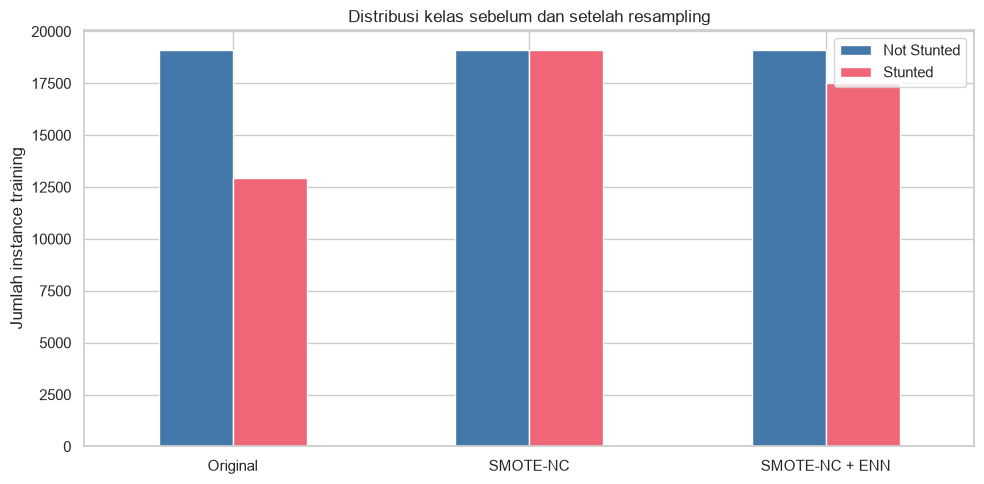

In [36]:
resampling_distribution = pd.DataFrame({
    name: pd.Series(target).value_counts().reindex([0, 1], fill_value=0)
    for name, target in [("Original", demo_y_original), ("SMOTE-NC", demo_y_nc),
                         ("SMOTE-NC + ENN", demo_y_ncenn)]}).T
resampling_distribution.columns = LABELS
display(resampling_distribution)
ax = resampling_distribution.plot.bar(rot=0, color=["#4477AA", "#EE6677"])
ax.set_ylabel("Jumlah instance training")
ax.set_title("Distribusi kelas sebelum dan setelah resampling")
plt.tight_layout()
plt.show()

## 6.5 Validasi Fitur Kategorikal Setelah Synthetic Oversampling
Nilai Gender harus tetap {0, 1}, termasuk baris sintetis. Tidak dilakukan pembulatan nilai
pecahan untuk menyembunyikan kesalahan encoding.

In [37]:
for name, frame in [("SMOTE-NC", demo_X_nc), ("SMOTE-NC + ENN", demo_X_ncenn)]:
    checked_features(frame)
    print("Gender unique setelah", name, ":", sorted(frame["Gender"].unique().tolist()))

Gender unique setelah SMOTE-NC : [0, 1]
Gender unique setelah SMOTE-NC + ENN : [0, 1]


## 6.6 Validasi Test Set Tetap Utuh
Demonstrasi selesai; seluruh input asli harus identik dengan snapshot.

In [38]:
assert_original_data()
print("Test set tetap utuh:", n_test_original, "baris.")

Test set tetap utuh: 8013 baris.


# 7. Hyperparameter Tuning
## 7.1 StratifiedKFold dan Grid yang Setara
StratifiedKFold(5, shuffle=True, random_state=42) dimaterialisasi sekali agar indeks fold
identik pada delapan eksperimen. GridSearchCV selalu menerima X_train/y_train asli.
Scoring `f1` menggunakan kelas positif 1 pada target biner; refit memilih mean CV F1 tertinggi.
Tidak ada tuning threshold atau early stopping menggunakan test.

Masing-masing grid memiliki 81 kandidat × 5 fold, total 3.240 fit CV + 8 refit.
Untuk efisiensi, cache pipeline disimpan sementara dan dikosongkan setiap eksperimen.
Cache hanya menggunakan hasil fit training fold yang identik; tidak menyatukan fold atau
memakai hasil demo. Empat worker thread grid dan satu thread model diterapkan sama pada semua skenario.
Backend threading menghindari masalah cleanup proses loky pada lingkungan Windows ini.
Waktu tuning adalah wall-clock seluruh search termasuk refit/cache; waktu refit dicatat terpisah.
Waktu tetap dipengaruhi beban mesin dan bukan benchmark statistik.

In [39]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_splits = list(skf.split(X_train, y_train))
validation_seen = np.zeros(len(X_train), dtype=int)
for train_idx, valid_idx in cv_splits:
    assert not np.intersect1d(train_idx, valid_idx).size
    assert y_train.iloc[train_idx].value_counts().min() > 5
    validation_seen[valid_idx] += 1
assert np.all(validation_seen == 1)
xgb_grid = {
    "model__n_estimators": [100, 200, 300],
    "model__max_depth": [3, 5, 7],
    "model__learning_rate": [0.05, 0.1, 0.2],
    "model__gamma": [0, 0.1, 0.3],
}
lgbm_grid = {
    "model__n_estimators": [100, 200, 300],
    "model__max_depth": [3, 5, 7],
    "model__learning_rate": [0.05, 0.1, 0.2],
    "model__num_leaves": [15, 31, 63],
}
PARAM_GRIDS = {"XGBoost": xgb_grid, "LightGBM": lgbm_grid}
assert all(len(ParameterGrid(grid)) == 81 for grid in PARAM_GRIDS.values())
searches, tuning_times = {}, {}

def tune_experiment(algorithm, method):
    assert_original_data()
    key = (algorithm, method)
    print("Mulai:", algorithm, "—", method, flush=True)
    with TemporaryDirectory(prefix="cv_cache_", dir=RUN_DIR) as cache_dir:
        pipeline = make_pipeline(algorithm, method, memory=Memory(cache_dir, verbose=0))
        search = GridSearchCV(
            pipeline, PARAM_GRIDS[algorithm], scoring="f1", cv=cv_splits,
            n_jobs=GRID_N_JOBS, pre_dispatch=GRID_N_JOBS, refit=True,
            error_score="raise", return_train_score=False, verbose=1)
        start = time.perf_counter()
        # Worker berbasis thread tidak membuat file memmap/proses loky.
        with threadpool_limits(limits=1), parallel_config(backend="threading"):
            search.fit(X_train, y_train)
        elapsed = time.perf_counter() - start
        # Prediksi tidak memerlukan cache; lepaskan lokasi sementara dari estimator.
        search.best_estimator_.memory = None
        search.estimator.memory = None
    assert_original_data()
    assert np.isfinite(search.cv_results_["mean_test_score"]).all()
    searches[key] = search
    tuning_times[key] = elapsed
    print("Best CV F1:", search.best_score_)
    print("Best hyperparameters:", search.best_params_)
    print(f"Tuning: {elapsed:.2f} s; refit: {search.refit_time_:.2f} s")
    slug = algorithm.lower() + "_" + str(METHODS.index(method) + 1)
    pd.DataFrame(search.cv_results_).to_csv(RUN_DIR / f"cv_{slug}.csv", index=False)

## 7.2 XGBoost — Baseline
Tuning memakai fold dan grid tetap untuk XGBoost; hanya strategi imbalance yang berubah.
Input tetap training asli. Evaluasi test dilakukan setelah seluruh tuning selesai.

In [40]:
tune_experiment('XGBoost', 'Baseline')

Mulai: XGBoost — Baseline
Fitting 5 folds for each of 81 candidates, totalling 405 fits
Best CV F1: 0.9507935629754479
Best hyperparameters: {'model__gamma': 0.1, 'model__learning_rate': 0.1, 'model__max_depth': 7, 'model__n_estimators': 300}
Tuning: 31.41 s; refit: 0.51 s


## 7.3 XGBoost — Class Weight
Tuning memakai fold dan grid tetap untuk XGBoost; hanya strategi imbalance yang berubah.
Input tetap training asli. Evaluasi test dilakukan setelah seluruh tuning selesai.

In [41]:
tune_experiment('XGBoost', 'Class Weight')

Mulai: XGBoost — Class Weight
Fitting 5 folds for each of 81 candidates, totalling 405 fits
Best CV F1: 0.948610470299162
Best hyperparameters: {'model__gamma': 0.3, 'model__learning_rate': 0.05, 'model__max_depth': 7, 'model__n_estimators': 300}
Tuning: 30.57 s; refit: 0.46 s


## 7.4 XGBoost — SMOTE-NC
Tuning memakai fold dan grid tetap untuk XGBoost; hanya strategi imbalance yang berubah.
Input tetap training asli. Evaluasi test dilakukan setelah seluruh tuning selesai.

In [42]:
tune_experiment('XGBoost', 'SMOTE-NC')

Mulai: XGBoost — SMOTE-NC
Fitting 5 folds for each of 81 candidates, totalling 405 fits
Best CV F1: 0.948287268587914
Best hyperparameters: {'model__gamma': 0, 'model__learning_rate': 0.2, 'model__max_depth': 7, 'model__n_estimators': 100}
Tuning: 61.96 s; refit: 2.66 s


## 7.5 XGBoost — SMOTE-NC + ENN
Tuning memakai fold dan grid tetap untuk XGBoost; hanya strategi imbalance yang berubah.
Input tetap training asli. Evaluasi test dilakukan setelah seluruh tuning selesai.

In [43]:
tune_experiment('XGBoost', 'SMOTE-NC + ENN')

Mulai: XGBoost — SMOTE-NC + ENN
Fitting 5 folds for each of 81 candidates, totalling 405 fits
Best CV F1: 0.9465588929112598
Best hyperparameters: {'model__gamma': 0.3, 'model__learning_rate': 0.2, 'model__max_depth': 3, 'model__n_estimators': 300}
Tuning: 58.69 s; refit: 2.56 s


## 7.6 LightGBM — Baseline
Tuning memakai fold dan grid tetap untuk LightGBM; hanya strategi imbalance yang berubah.
Input tetap training asli. Evaluasi test dilakukan setelah seluruh tuning selesai.

In [44]:
tune_experiment('LightGBM', 'Baseline')

Mulai: LightGBM — Baseline
Fitting 5 folds for each of 81 candidates, totalling 405 fits
Best CV F1: 0.9507148636894593
Best hyperparameters: {'model__learning_rate': 0.1, 'model__max_depth': 5, 'model__n_estimators': 300, 'model__num_leaves': 63}
Tuning: 35.76 s; refit: 0.34 s


## 7.7 LightGBM — Class Weight
Tuning memakai fold dan grid tetap untuk LightGBM; hanya strategi imbalance yang berubah.
Input tetap training asli. Evaluasi test dilakukan setelah seluruh tuning selesai.

In [45]:
tune_experiment('LightGBM', 'Class Weight')

Mulai: LightGBM — Class Weight
Fitting 5 folds for each of 81 candidates, totalling 405 fits
Best CV F1: 0.9490434758703437
Best hyperparameters: {'model__learning_rate': 0.1, 'model__max_depth': 7, 'model__n_estimators': 200, 'model__num_leaves': 63}
Tuning: 35.12 s; refit: 0.31 s


## 7.8 LightGBM — SMOTE-NC
Tuning memakai fold dan grid tetap untuk LightGBM; hanya strategi imbalance yang berubah.
Input tetap training asli. Evaluasi test dilakukan setelah seluruh tuning selesai.

In [46]:
tune_experiment('LightGBM', 'SMOTE-NC')

Mulai: LightGBM — SMOTE-NC
Fitting 5 folds for each of 81 candidates, totalling 405 fits
Best CV F1: 0.9488281007313235
Best hyperparameters: {'model__learning_rate': 0.05, 'model__max_depth': 7, 'model__n_estimators': 300, 'model__num_leaves': 63}
Tuning: 51.44 s; refit: 2.66 s


## 7.9 LightGBM — SMOTE-NC + ENN
Tuning memakai fold dan grid tetap untuk LightGBM; hanya strategi imbalance yang berubah.
Input tetap training asli. Evaluasi test dilakukan setelah seluruh tuning selesai.

In [47]:
tune_experiment('LightGBM', 'SMOTE-NC + ENN')

Mulai: LightGBM — SMOTE-NC + ENN
Fitting 5 folds for each of 81 candidates, totalling 405 fits
Best CV F1: 0.9462296771556705
Best hyperparameters: {'model__learning_rate': 0.2, 'model__max_depth': 5, 'model__n_estimators': 200, 'model__num_leaves': 15}
Tuning: 50.33 s; refit: 2.45 s


# 8. Model Evaluation & Comparison
## 8.1 Tabel Hasil Semua Model
Semua model terbaik telah di-refit oleh GridSearchCV. Helper tunggal hanya melakukan prediksi,
tanpa fit ulang, pada test asli. Precision, Recall, dan F1 dihitung untuk Stunted (1),
ROC-AUC dari `predict_proba(X_test)[:, 1]`. Prediksi kelas memakai aturan default classifier
yang sama antar-skenario; tidak ada optimasi threshold. Tabel menyorot maksimum F1 dan Recall;
ranking deskriptif tidak dipakai untuk tuning ulang pada test.

In [48]:
assert_original_data()
assert len(searches) == 8
predictions, probabilities = {}, {}

def evaluate_on_test(algorithm, method, search):
    model = search.best_estimator_
    assert np.array_equal(model.classes_, [0, 1])
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]
    assert len(pred) == len(proba) == n_test_original
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
    assert tn + fp + fn + tp == n_test_original
    predictions[(algorithm, method)] = pred
    probabilities[(algorithm, method)] = proba
    return {
        "Model": algorithm, "Imbalance Method": method,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, pos_label=POS_LABEL, zero_division=0),
        "Recall": recall_score(y_test, pred, pos_label=POS_LABEL, zero_division=0),
        "F1": f1_score(y_test, pred, pos_label=POS_LABEL, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, proba),
        "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
        "Best CV F1": search.best_score_, "Tuning Time": tuning_times[(algorithm, method)],
        "Refit Time": search.refit_time_, "Best Hyperparameters": search.best_params_,
    }

results = pd.DataFrame([evaluate_on_test(a, m, searches[(a, m)])
                        for a in ALGORITHMS for m in METHODS])
metric_columns = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC", "Best CV F1"]
table_columns = ["Model", "Imbalance Method", "Accuracy", "Precision", "Recall", "F1",
                 "ROC-AUC", "TN", "FP", "FN", "TP", "Best CV F1", "Tuning Time"]
display(results[table_columns].style.format({c: "{:.4f}" for c in metric_columns} |
        {"Tuning Time": "{:.2f}"}).highlight_max(subset=["F1", "Recall"], color="#c6e5c4"))
display(results[["Model", "Imbalance Method", "Best Hyperparameters"]])
display(results.sort_values(["F1", "Recall"], ascending=False)[table_columns])
assert_original_data()

,Model,Imbalance Method,Accuracy,Precision,Recall,F1,ROC-AUC,TN,FP,FN,TP,Best CV F1,Tuning Time
0,XGBoost,Baseline,0.9609,0.9612,0.9414,0.9512,0.9928,4650,123,190,3050,0.9508,31.41
1,XGBoost,Class Weight,0.9579,0.9476,0.9485,0.9480,0.9926,4603,170,167,3073,0.9486,30.57
2,XGBoost,SMOTE-NC,0.9578,0.9459,0.9500,0.9480,0.9926,4597,176,162,3078,0.9483,61.96
3,XGBoost,SMOTE-NC + ENN,0.9568,0.9668,0.9250,0.9454,0.9911,4670,103,243,2997,0.9466,58.69
4,LightGBM,Baseline,0.9613,0.9584,0.9454,0.9518,0.9932,4640,133,177,3063,0.9507,35.76
5,LightGBM,Class Weight,0.9611,0.9469,0.9574,0.9521,0.9934,4599,174,138,3102,0.9490,35.12
6,LightGBM,SMOTE-NC,0.9577,0.9453,0.9503,0.9478,0.9930,4595,178,161,3079,0.9488,51.44
7,LightGBM,SMOTE-NC + ENN,0.9586,0.9690,0.9272,0.9476,0.9912,4677,96,236,3004,0.9462,50.33


,Model,Imbalance Method,Best Hyperparameters
0,XGBoost,Baseline,"{'model__gamma': 0.1, 'model__learning_rate': ..."
1,XGBoost,Class Weight,"{'model__gamma': 0.3, 'model__learning_rate': ..."
2,XGBoost,SMOTE-NC,"{'model__gamma': 0, 'model__learning_rate': 0...."
3,XGBoost,SMOTE-NC + ENN,"{'model__gamma': 0.3, 'model__learning_rate': ..."
4,LightGBM,Baseline,"{'model__learning_rate': 0.1, 'model__max_dept..."
5,LightGBM,Class Weight,"{'model__learning_rate': 0.1, 'model__max_dept..."
6,LightGBM,SMOTE-NC,"{'model__learning_rate': 0.05, 'model__max_dep..."
7,LightGBM,SMOTE-NC + ENN,"{'model__learning_rate': 0.2, 'model__max_dept..."


,Model,Imbalance Method,Accuracy,Precision,Recall,F1,ROC-AUC,TN,FP,FN,TP,Best CV F1,Tuning Time
5,LightGBM,Class Weight,0.961063,0.946886,0.957407,0.952118,0.993406,4599,174,138,3102,0.949043,35.121548
4,LightGBM,Baseline,0.961313,0.958385,0.945370,0.951833,0.993246,4640,133,177,3063,0.950715,35.764705
0,XGBoost,Baseline,0.960938,0.961235,0.941358,0.951193,0.992779,4650,123,190,3050,0.950794,31.413024
1,XGBoost,Class Weight,0.957943,0.947579,0.948457,0.948018,0.992650,4603,170,167,3073,0.948610,30.567536
2,XGBoost,SMOTE-NC,0.957819,0.945913,0.950000,0.947952,0.992607,4597,176,162,3078,0.948287,61.955674
6,LightGBM,SMOTE-NC,0.957694,0.945348,0.950309,0.947822,0.993028,4595,178,161,3079,0.948828,51.443674
7,LightGBM,SMOTE-NC + ENN,0.958567,0.969032,0.927160,0.947634,0.991219,4677,96,236,3004,0.946230,50.325977
3,XGBoost,SMOTE-NC + ENN,0.956820,0.966774,0.925000,0.945426,0.991055,4670,103,243,2997,0.946559,58.694110


## 8.2 Confusion Matrix
Baris = aktual, kolom = prediksi, label berurutan Not Stunted lalu Stunted.
Orientasi setiap matriks: TN FP / FN TP. Skala warna sama untuk delapan panel.

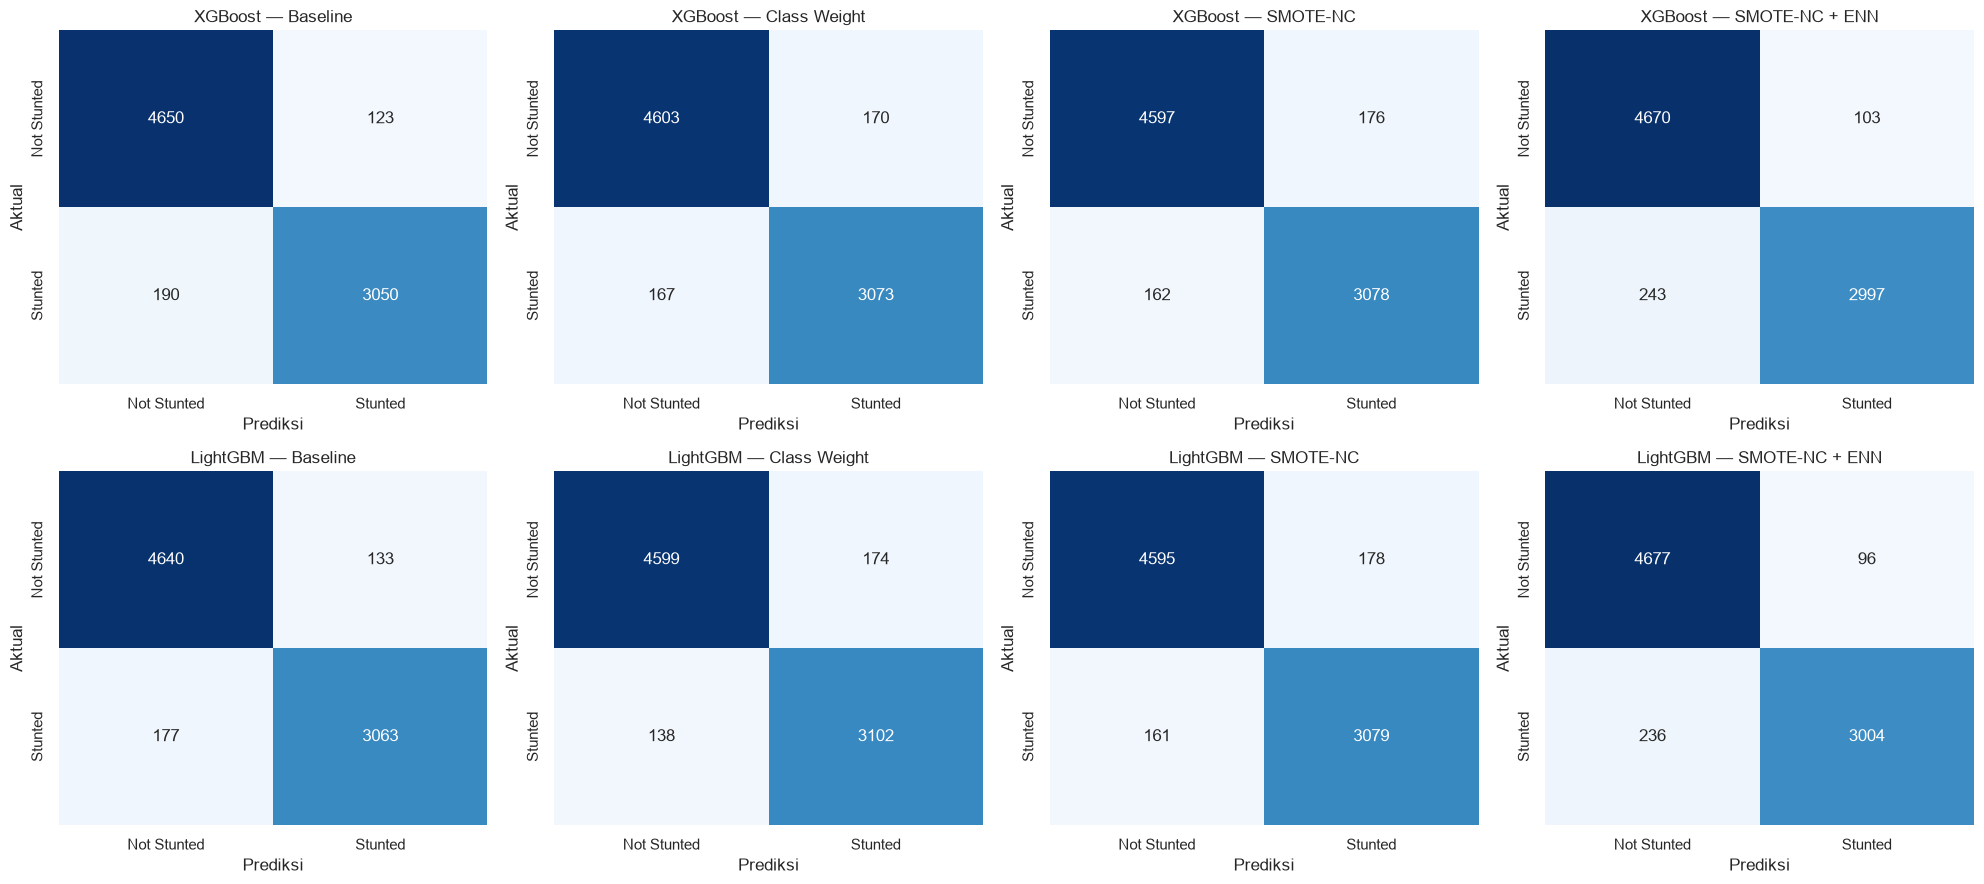

In [49]:
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
cm_max = max(confusion_matrix(y_test, p, labels=[0, 1]).max() for p in predictions.values())
for ax, (key, pred) in zip(axes.ravel(), predictions.items()):
    sns.heatmap(confusion_matrix(y_test, pred, labels=[0, 1]), annot=True, fmt="d",
                cmap="Blues", vmin=0, vmax=cm_max, cbar=False,
                xticklabels=LABELS, yticklabels=LABELS, ax=ax)
    ax.set_title(" — ".join(key))
    ax.set_xlabel("Prediksi")
    ax.set_ylabel("Aktual")
plt.tight_layout()
fig.savefig(RUN_DIR / "confusion_matrices.png", dpi=200, bbox_inches="tight")
plt.show()

## 8.3 ROC Curve
Dua panel dengan sumbu dan warna skenario identik agar empat kurva tiap algoritma mudah dibaca.

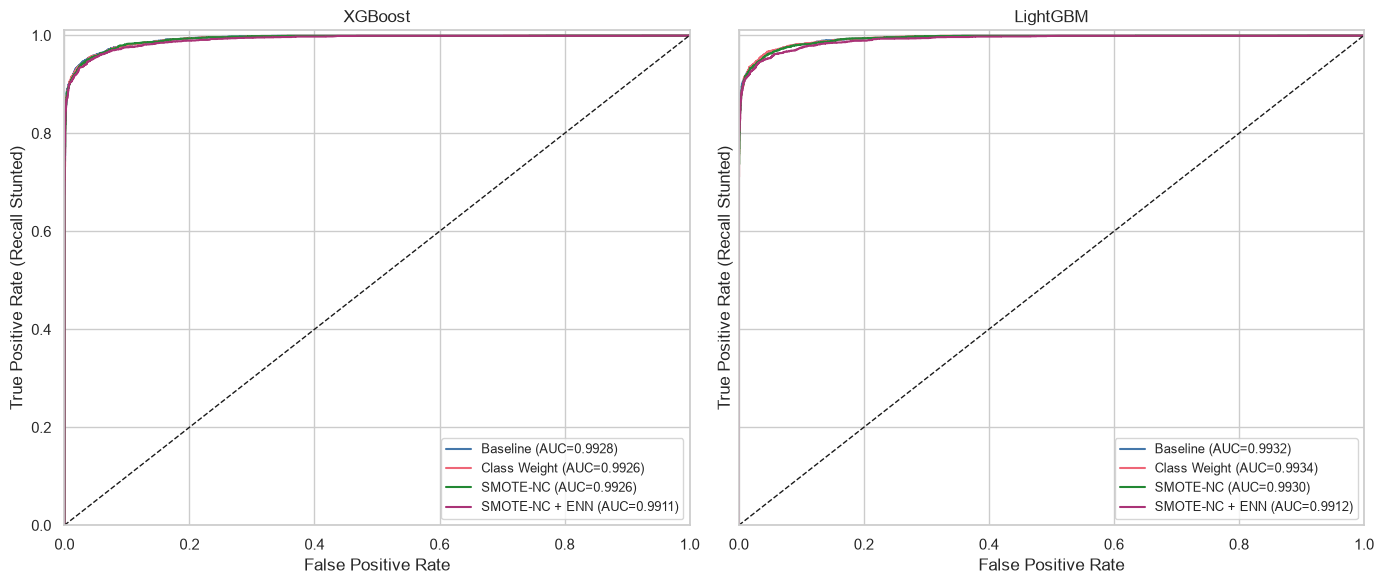

In [50]:
COLORS = dict(zip(METHODS, ["#4477AA", "#EE6677", "#228833", "#AA3377"]))
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=True, sharey=True)
for ax, algorithm in zip(axes, ALGORITHMS):
    for method in METHODS:
        proba = probabilities[(algorithm, method)]
        fpr, tpr, _ = roc_curve(y_test, proba, pos_label=POS_LABEL)
        auc = roc_auc_score(y_test, proba)
        ax.plot(fpr, tpr, color=COLORS[method], label=f"{method} (AUC={auc:.4f})")
    ax.plot([0, 1], [0, 1], "k--", lw=1)
    ax.set(xlim=(0, 1), ylim=(0, 1.01), title=algorithm,
           xlabel="False Positive Rate", ylabel="True Positive Rate (Recall Stunted)")
    ax.legend(loc="lower right", fontsize=9)
plt.tight_layout()
fig.savefig(RUN_DIR / "roc_curves.png", dpi=200, bbox_inches="tight")
plt.show()

## 8.4 Perbandingan Recall Stunted
Delapan kombinasi ditampilkan dengan sumbu 0–1 agar perbedaan tidak dibesar-besarkan.

In [51]:
def plot_comparison(metric, ylabel, filename, unit_interval=True):
    values = results.pivot(index="Model", columns="Imbalance Method", values=metric)
    values = values.reindex(index=ALGORITHMS, columns=METHODS)
    ax = values.plot.bar(color=[COLORS[m] for m in METHODS], figsize=(11, 5), rot=0)
    ax.set_ylabel(ylabel)
    ax.set_xlabel("Algoritma")
    ax.set_title("Perbandingan " + ylabel)
    if unit_interval:
        ax.set_ylim(0, 1.08)
    for container in ax.containers:
        ax.bar_label(container, fmt="%.4f" if unit_interval else "%.1f", fontsize=8, padding=2)
    ax.legend(title="Strategi imbalance", loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=4)
    plt.tight_layout()
    ax.figure.savefig(RUN_DIR / filename, dpi=200, bbox_inches="tight")
    plt.show()

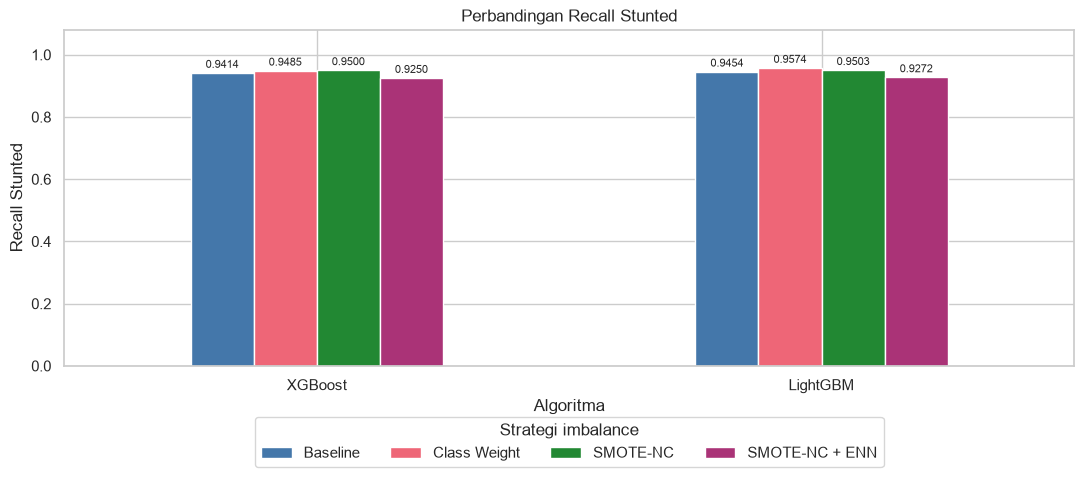

In [52]:
plot_comparison('Recall', 'Recall Stunted', 'recall.png')

## 8.5 Perbandingan F1-Score Stunted
Delapan kombinasi ditampilkan dengan sumbu 0–1 agar perbedaan tidak dibesar-besarkan.

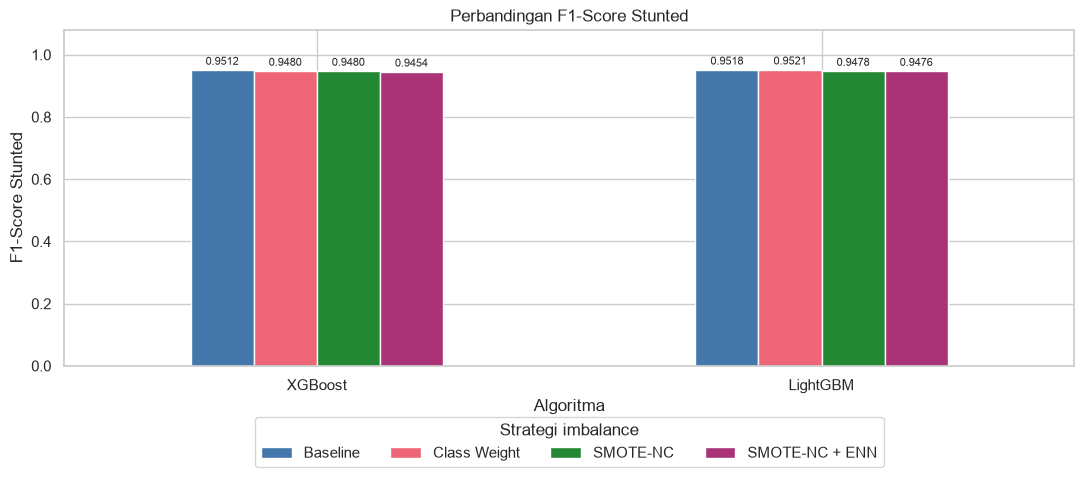

In [53]:
plot_comparison('F1', 'F1-Score Stunted', 'f1.png')

## 8.6 Perbandingan ROC-AUC
Delapan kombinasi ditampilkan dengan sumbu 0–1 agar perbedaan tidak dibesar-besarkan.

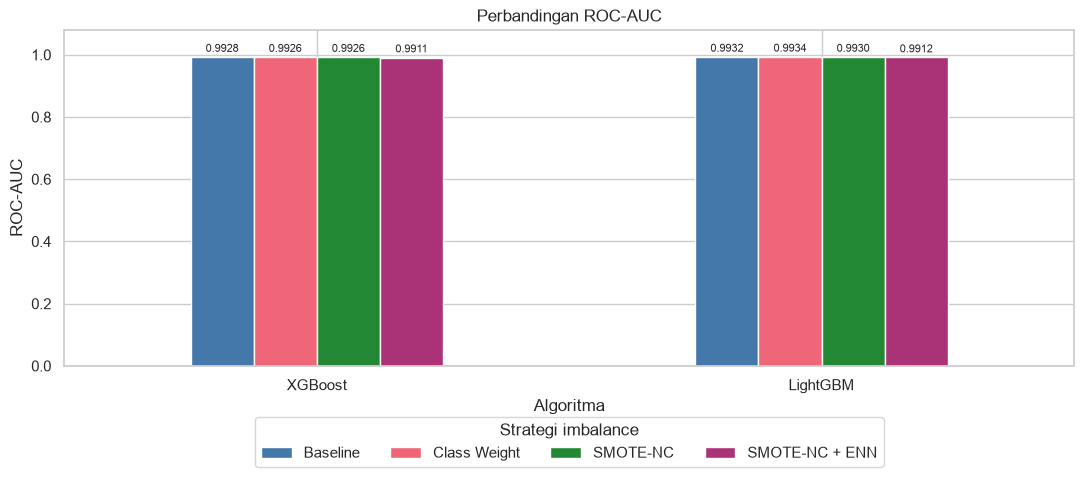

In [54]:
plot_comparison('ROC-AUC', 'ROC-AUC', 'roc_auc.png')

## 8.7 Training/Tuning Time
Waktu tuning mencakup search dan refit; refit adalah waktu training final pipeline terbaik
pada training lengkap, termasuk resampling bila ada. Cache fold dapat mempercepat kandidat
berikutnya; seluruh skenario memakai kebijakan cache yang sama dan dimulai dengan cache kosong.

,Model,Imbalance Method,Tuning Time,Refit Time
0,XGBoost,Baseline,31.413024,0.507645
1,XGBoost,Class Weight,30.567536,0.460608
2,XGBoost,SMOTE-NC,61.955674,2.655133
3,XGBoost,SMOTE-NC + ENN,58.694110,2.563453
4,LightGBM,Baseline,35.764705,0.340991
5,LightGBM,Class Weight,35.121548,0.314420
6,LightGBM,SMOTE-NC,51.443674,2.659684
7,LightGBM,SMOTE-NC + ENN,50.325977,2.448579


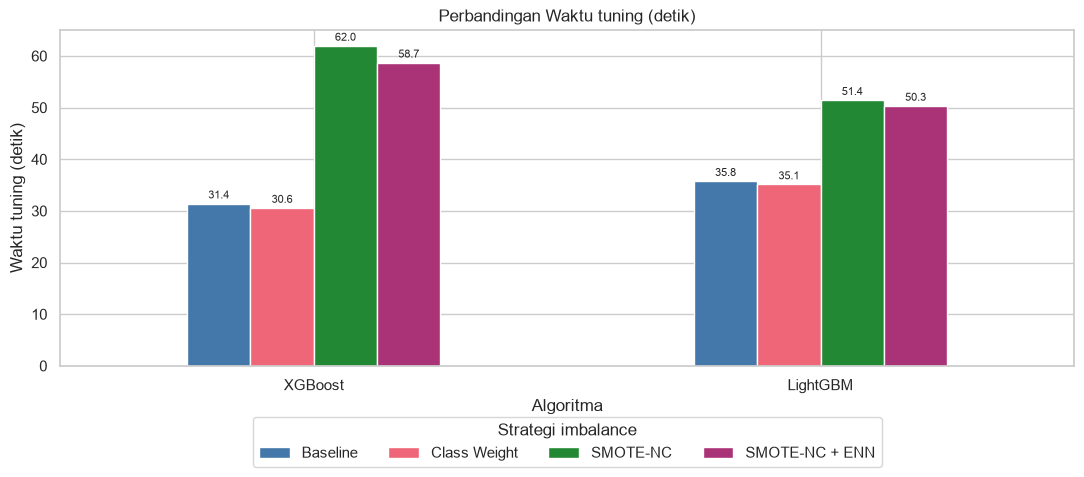

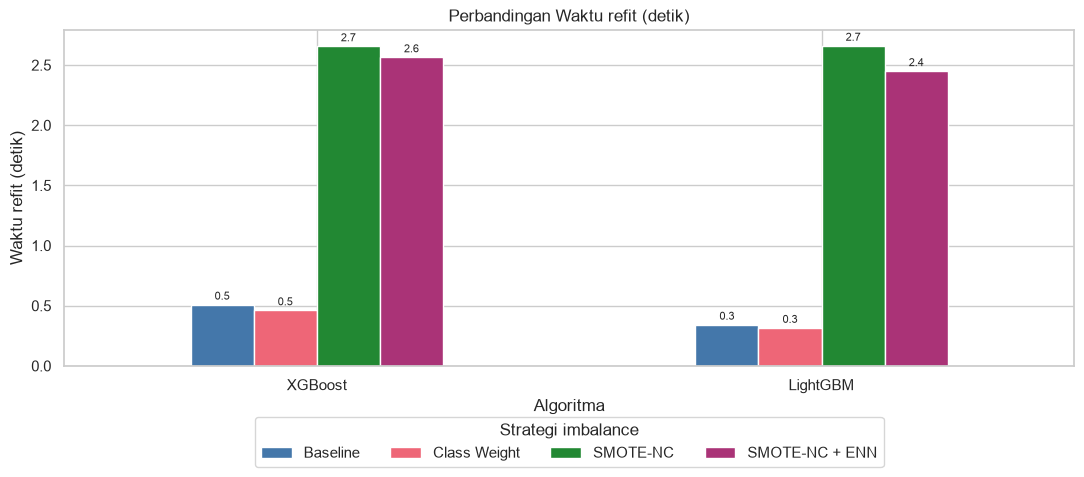

In [55]:
display(results[["Model", "Imbalance Method", "Tuning Time", "Refit Time"]])
plot_comparison("Tuning Time", "Waktu tuning (detik)", "tuning_time.png", unit_interval=False)
plot_comparison("Refit Time", "Waktu refit (detik)", "refit_time.png", unit_interval=False)

## 8.8 Interpretasi Hasil Otomatis
Prioritas interpretasi: Recall Stunted, F1, ROC-AUC, Precision, lalu Accuracy. False Negative
adalah balita berlabel Stunted yang diprediksi Not Stunted. F1 tetap menjadi kriteria pemilihan
hyperparameter yang ditetapkan sebelum evaluasi. Semua selisih di bawah dihitung dari hasil aktual.
Selisih positif disebut peningkatan numerik, bukan bukti signifikansi statistik atau manfaat klinis.
Satu split tidak cukup membuktikan kebutuhan resampling secara umum; tidak ada uji inferensial
atau validasi eksternal dalam protokol ini. Peringkat test bersifat deskriptif dan tidak mengubah model.

In [56]:
interpretation_lines = []
def report(text):
    interpretation_lines.append(text)
    print(text)

for number, metric in [(1, "Recall"), (2, "F1"), (3, "ROC-AUC")]:
    best_value = results[metric].max()
    winners = results.loc[results[metric] == best_value]
    names = "; ".join(winners["Model"] + " — " + winners["Imbalance Method"])
    report(f"{number}. {metric} tertinggi: {names} ({best_value:.6f}).")

indexed = results.set_index(["Model", "Imbalance Method"])
comparison_rows = []
for number, candidate, reference in [
        (4, "Class Weight", "Baseline"), (5, "SMOTE-NC", "Baseline"),
        (6, "SMOTE-NC + ENN", "SMOTE-NC"), (7, "SMOTE-NC", "Class Weight")]:
    report(f"{number}. {candidate} dibanding {reference}:")
    for algorithm in ALGORITHMS:
        delta = indexed.loc[(algorithm, candidate), metric_columns] - indexed.loc[(algorithm, reference), metric_columns]
        recall_status = "naik" if delta["Recall"] > 0 else "turun" if delta["Recall"] < 0 else "tetap"
        f1_status = "naik" if delta["F1"] > 0 else "turun" if delta["F1"] < 0 else "tetap"
        report(f"   {algorithm}: Recall {recall_status} ({delta['Recall']:+.6f}); "
               f"F1 {f1_status} ({delta['F1']:+.6f}); Precision {delta['Precision']:+.6f}.")
        comparison_rows.append({"Model": algorithm, "Candidate": candidate,
                                "Reference": reference, **{f"Delta {k}": float(v) for k,v in delta.items()}})
report("7 (lanjutan). Efektivitas algorithm-level vs data-level dibaca dari selisih SMOTE-NC "
       "terhadap Class Weight di atas: positif mengunggulkan SMOTE-NC pada metrik tersebut, "
       "negatif mengunggulkan Class Weight; bila Recall/F1 berbeda arah, tidak ada pemenang tunggal.")
report("8. Dampak ENN:")
for algorithm in ALGORITHMS:
    plain = indexed.loc[(algorithm, "SMOTE-NC")]
    enn = indexed.loc[(algorithm, "SMOTE-NC + ENN")]
    report(f"   {algorithm}: Delta Recall={enn['Recall']-plain['Recall']:+.6f}, "
           f"Delta F1={enn['F1']-plain['F1']:+.6f}, Delta FN={int(enn['FN']-plain['FN']):+d}.")
report("   Kebermaknaan statistik/praktis belum dapat ditetapkan dari satu split dan tanpa ambang manfaat yang ditentukan sebelumnya.")
report("9. Apakah resampling diperlukan pada dataset ini?")
for algorithm in ALGORITHMS:
    group = results[results["Model"] == algorithm]
    no_sampling = group[group["Imbalance Method"].isin(["Baseline", "Class Weight"])]
    sampling = group[group["Imbalance Method"].isin(["SMOTE-NC", "SMOTE-NC + ENN"])]
    nr = no_sampling.sort_values(["F1", "Recall"], ascending=False).iloc[0]
    sr = sampling.sort_values(["F1", "Recall"], ascending=False).iloc[0]
    verdict = "ada keuntungan F1 numerik dari resampling" if sr["F1"] > nr["F1"] else "resampling tidak diperlukan untuk mencapai F1 terbaik pada split ini"
    report(f"   {algorithm}: {verdict}; {sr['Imbalance Method']} vs {nr['Imbalance Method']}: "
           f"Delta F1={sr['F1']-nr['F1']:+.6f}, Delta Recall={sr['Recall']-nr['Recall']:+.6f}.")
report("10. Trade-off terhadap Baseline:")
for algorithm in ALGORITHMS:
    baseline = indexed.loc[(algorithm, "Baseline")]
    for method in METHODS[1:]:
        row = indexed.loc[(algorithm, method)]
        dr, dp = row["Recall"]-baseline["Recall"], row["Precision"]-baseline["Precision"]
        status = "trade-off Recall–Precision" if dr * dp < 0 else "tidak ada perubahan berlawanan arah Recall–Precision"
        report(f"   {algorithm} — {method}: {status}; Delta Recall={dr:+.6f}, Delta Precision={dp:+.6f}.")
comparison_deltas = pd.DataFrame(comparison_rows)
display(comparison_deltas)
assert_original_data()

1. Recall tertinggi: LightGBM — Class Weight (0.957407).
2. F1 tertinggi: LightGBM — Class Weight (0.952118).
3. ROC-AUC tertinggi: LightGBM — Class Weight (0.993406).
4. Class Weight dibanding Baseline:
   XGBoost: Recall naik (+0.007099); F1 turun (-0.003175); Precision -0.013656.
   LightGBM: Recall naik (+0.012037); F1 naik (+0.000284); Precision -0.011499.
5. SMOTE-NC dibanding Baseline:
   XGBoost: Recall naik (+0.008642); F1 turun (-0.003241); Precision -0.015323.
   LightGBM: Recall naik (+0.004938); F1 turun (-0.004011); Precision -0.013037.
6. SMOTE-NC + ENN dibanding SMOTE-NC:
   XGBoost: Recall turun (-0.025000); F1 turun (-0.002526); Precision +0.020861.
   LightGBM: Recall turun (-0.023148); F1 turun (-0.000188); Precision +0.023684.
7. SMOTE-NC dibanding Class Weight:
   XGBoost: Recall naik (+0.001543); F1 turun (-0.000066); Precision -0.001667.
   LightGBM: Recall turun (-0.007099); F1 turun (-0.004296); Precision -0.001538.
7 (lanjutan). Efektivitas algorithm-level vs

,Model,Candidate,Reference,Delta Accuracy,Delta Precision,Delta Recall,Delta F1,Delta ROC-AUC,Delta Best CV F1
0,XGBoost,Class Weight,Baseline,-0.002995,-0.013656,0.007099,-0.003175,-0.000130,-0.002183
1,LightGBM,Class Weight,Baseline,-0.000250,-0.011499,0.012037,0.000284,0.000160,-0.001671
2,XGBoost,SMOTE-NC,Baseline,-0.003120,-0.015323,0.008642,-0.003241,-0.000172,-0.002506
3,LightGBM,SMOTE-NC,Baseline,-0.003619,-0.013037,0.004938,-0.004011,-0.000218,-0.001887
4,XGBoost,SMOTE-NC + ENN,SMOTE-NC,-0.000998,0.020861,-0.025000,-0.002526,-0.001552,-0.001728
5,LightGBM,SMOTE-NC + ENN,SMOTE-NC,0.000874,0.023684,-0.023148,-0.000188,-0.001809,-0.002598
6,XGBoost,SMOTE-NC,Class Weight,-0.000125,-0.001667,0.001543,-0.000066,-0.000042,-0.000323
7,LightGBM,SMOTE-NC,Class Weight,-0.003370,-0.001538,-0.007099,-0.004296,-0.000378,-0.000215


### Artefak dan Reproducibility
Simpan metrik, hasil CV seluruh kandidat, parameter terbaik, prediksi test, manifest versi,
dan grafik ke `results/master_v2`. Artefak dihitung dari eksekusi saat ini; tidak digunakan
sebagai input training. Master asli tetap utuh. Versi package dan hash data membantu audit,
tetapi reproduksi lintas versi library/mesin dapat menghasilkan perbedaan numerik kecil.

In [57]:
results.to_csv(RUN_DIR / "comparison.csv", index=False)
comparison_deltas.to_csv(RUN_DIR / "comparison_deltas.csv", index=False)
resampling_distribution.to_csv(RUN_DIR / "resampling_distribution.csv")
best_parameters = {f"{a} — {m}": searches[(a, m)].best_params_ for a in ALGORITHMS for m in METHODS}
(RUN_DIR / "best_parameters.json").write_text(json.dumps(best_parameters, indent=2), encoding="utf-8")
test_predictions = pd.DataFrame({"row_index": y_test.index, "y_true": y_test.to_numpy()})
for (a, m), pred in predictions.items():
    test_predictions[f"{a} — {m} prediction"] = pred
    test_predictions[f"{a} — {m} probability"] = probabilities[(a, m)]
test_predictions.to_csv(RUN_DIR / "test_predictions.csv", index=False)
manifest = {
    "python": sys.version, "packages": dependency_versions,
    "dataset_sha256": hashlib.sha256(DATA_PATH.read_bytes()).hexdigest(),
    "random_state": RANDOM_STATE, "test_size": TEST_SIZE,
    "raw_rows": len(df), "clean_rows": len(df_clean), "train_rows": len(X_train),
    "test_rows": len(X_test), "features": FEATURES, "positive_label": POS_LABEL,
    "scale_pos_weight": scale_pos_weight, "scoring": "f1", "cv_folds": 5,
    "grid_n_jobs": GRID_N_JOBS, "model_n_jobs": MODEL_N_JOBS,
    "xgb_grid": xgb_grid, "lgbm_grid": lgbm_grid,
    "train_indices": X_train.index.tolist(), "test_indices": X_test.index.tolist(),
}
(RUN_DIR / "run_manifest.json").write_text(json.dumps(manifest, indent=2), encoding="utf-8")
(RUN_DIR / "interpretation.txt").write_text("\n".join(interpretation_lines), encoding="utf-8")
assert_original_data()
print("Selesai: 8 eksperimen. Test tetap identik:", n_test_original, "baris.")
print("Artefak:", RUN_DIR)

Selesai: 8 eksperimen. Test tetap identik: 8013 baris.
Artefak: d:\Kuliah\Semester9\Notebook\results\master_v2


# 9. Penyimpanan Model Terlatih dengan Joblib

Bagian ini menyimpan **delapan pipeline terbaik yang sudah di-fit**, bukan melatih ulang.
Pipeline disimpan lengkap supaya konfigurasi model dan sampler tetap tercatat; saat prediksi,
sampler imbalanced-learn tidak dijalankan. Semua berkas berada di `RUN_DIR / "models"`:

- `best_models.joblib`: dictionary `(algorithm, method) → best_estimator_` untuk inference.
- `experiment_state.joblib`: dictionary `state` berisi `searches`, hasil evaluasi, prediksi,
  probabilitas, data train/test asli beserta snapshot dan konfigurasi yang diperlukan SHAP.
  Objek `GridSearchCV` mencakup estimator terlatih dan hasil CV, bukan hanya best parameters.
- `model_manifest.json`: versi dependency, daftar model, parameter terbaik, dan hash arsip.

Prasyarat: `searches` dan state eksperimen masih tersedia di kernel. **Output notebook dan CSV
bukan pengganti objek model.** Jika kernel kosong, cell berhenti dan tidak menjalankan training.
Jalankan cell ini setelah evaluasi selesai, sebelum menutup/reset kernel. Cell dapat dijalankan
sendiri bila state sudah tersedia; tidak perlu menjalankan ulang GridSearchCV.

Arsip ditulis sementara, dimuat kembali, lalu diverifikasi sebelum menggantikan berkas tujuan.
Prediksi kedelapan pipeline setelah load harus identik dengan prediksi test sebelumnya.
Joblib bergantung pada kompatibilitas versi Python/library; gunakan versi yang tercatat dan
muat hanya arsip yang tepercaya. Objek fungsi notebook tidak diserialisasi.


In [58]:
from pathlib import Path
from tempfile import TemporaryDirectory
from importlib.metadata import version
from datetime import datetime, timezone
import sys
import json
import hashlib
import joblib
import numpy as np
import pandas as pd

persistence_state_names = [
    "searches", "results", "predictions", "probabilities", "FEATURES", "RANDOM_STATE",
    "TEST_SIZE", "POS_LABEL", "LABELS", "X_train", "y_train", "X_test", "y_test",
    "X_train_snapshot", "y_train_snapshot", "X_test_snapshot", "y_test_snapshot",
    "n_test_original", "categorical_indices", "scale_pos_weight",
]
persistence_missing = [name for name in persistence_state_names + ["RUN_DIR", "assert_original_data"]
                       if name not in globals()]
if persistence_missing:
    raise RuntimeError("Model belum dapat disimpan: state kernel tidak tersedia: "
                       + ", ".join(persistence_missing)
                       + ". Gunakan kernel eksperimen yang sudah selesai; tidak ada training otomatis.")
assert_original_data()
assert len(searches) == len(results) == 8
assert set(searches) == set(predictions) == set(probabilities)
assert set(searches) == set(zip(results["Model"], results["Imbalance Method"]))
persisted_models = {key: search.best_estimator_ for key, search in searches.items()}
persistence_dir = Path(RUN_DIR) / "models"
persistence_dir.mkdir(parents=True, exist_ok=True)
persistence_metadata = {
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "python": sys.version, "random_state": RANDOM_STATE, "positive_class": POS_LABEL,
    "features": list(FEATURES), "test_rows": len(X_test),
    "packages": {name: version(name) for name in ["joblib", "numpy", "pandas",
                  "scikit-learn", "imbalanced-learn", "xgboost", "lightgbm"]},
    "models": [{"algorithm": key[0], "method": key[1],
                "best_parameters": search.best_params_, "best_cv_f1": float(search.best_score_)}
               for key, search in searches.items()],
}
persistence_bundle = {
    "format_version": 1,
    "metadata": persistence_metadata.copy(),
    "state": {name: globals()[name] for name in persistence_state_names},
}
with TemporaryDirectory(prefix="joblib_save_", dir=persistence_dir) as persistence_temp:
    persistence_temp = Path(persistence_temp)
    joblib.dump(persisted_models, persistence_temp / "best_models.joblib", compress=3)
    joblib.dump(persistence_bundle, persistence_temp / "experiment_state.joblib", compress=3)
    persistence_loaded_models = joblib.load(persistence_temp / "best_models.joblib")
    persistence_loaded_state = joblib.load(persistence_temp / "experiment_state.joblib")["state"]
    assert set(persistence_loaded_models) == set(searches)
    assert set(persistence_loaded_state["searches"]) == set(searches)
    pd.testing.assert_frame_equal(persistence_loaded_state["results"], results, check_exact=True)
    for persistence_name in ["X_train", "X_test", "X_train_snapshot", "X_test_snapshot"]:
        pd.testing.assert_frame_equal(persistence_loaded_state[persistence_name], globals()[persistence_name], check_exact=True)
    for persistence_name in ["y_train", "y_test", "y_train_snapshot", "y_test_snapshot"]:
        pd.testing.assert_series_equal(persistence_loaded_state[persistence_name], globals()[persistence_name], check_exact=True)
    for persistence_key in searches:
        np.testing.assert_array_equal(persistence_loaded_state["predictions"][persistence_key], predictions[persistence_key])
        np.testing.assert_array_equal(persistence_loaded_state["probabilities"][persistence_key], probabilities[persistence_key])
        # Verifikasi kedua arsip menyimpan estimator yang dapat dipakai tanpa fit ulang.
        for persistence_model in [persistence_loaded_models[persistence_key],
                                  persistence_loaded_state["searches"][persistence_key].best_estimator_]:
            assert np.array_equal(persistence_model.classes_, [0, 1])
            np.testing.assert_array_equal(persistence_model.predict(X_test), predictions[persistence_key])
            np.testing.assert_allclose(persistence_model.predict_proba(X_test)[:, 1],
                                       probabilities[persistence_key], rtol=1e-7, atol=1e-8)
    assert_original_data()
    persistence_metadata["validation"] = "passed: both archives reproduce all 8 test predictions and probabilities"
    persistence_metadata["sha256"] = {
        name: hashlib.sha256((persistence_temp / name).read_bytes()).hexdigest()
        for name in ["best_models.joblib", "experiment_state.joblib"]}
    (persistence_temp / "model_manifest.json").write_text(
        json.dumps(persistence_metadata, indent=2, ensure_ascii=False), encoding="utf-8")
    for persistence_filename in ["best_models.joblib", "experiment_state.joblib", "model_manifest.json"]:
        (persistence_temp / persistence_filename).replace(persistence_dir / persistence_filename)
del persistence_loaded_models, persistence_loaded_state, persistence_model
print("Delapan model tersimpan dan lolos verifikasi load tanpa training ulang:", persistence_dir)


Delapan model tersimpan dan lolos verifikasi load tanpa training ulang: d:\Kuliah\Semester9\Notebook\results\master_v2\models


### Memuat Kembali Model tanpa Training

Untuk inference, jalankan contoh berikut di kernel yang baru. Isi `MODEL_DIR` sesuai lokasi proyek.
Data prediksi harus sudah memakai empat fitur dan encoding yang sama seperti penelitian.

```python
from pathlib import Path
import joblib
MODEL_DIR = Path("D:/Kuliah/Semester9/Notebook/results/master_v2/models")
loaded_models = joblib.load(MODEL_DIR / "best_models.joblib")
print(list(loaded_models))
# Pilih key dari daftar tersebut; tidak diperlukan fit().
# probability = loaded_models[key].predict_proba(X_input)[:, 1]
```

Untuk melanjutkan **section 10 SHAP** di kernel baru tanpa mengulang eksperimen, muat state
tepercaya dan definisikan kembali helper validasi berikut. Path `RUN_DIR` ditentukan dari lokasi
arsip agar tidak bergantung pada direktori kerja kernel. Seluruh snapshot berasal dari arsip
eksperimen, bukan dibuat ulang dari data yang mungkin telah berubah.

```python
from pathlib import Path
import joblib
MODEL_DIR = Path("D:/Kuliah/Semester9/Notebook/results/master_v2/models")
saved_experiment = joblib.load(MODEL_DIR / "experiment_state.joblib")
assert saved_experiment["format_version"] == 1
globals().update(saved_experiment["state"])
RUN_DIR = MODEL_DIR.parent

def assert_original_data():
    assert X_test.equals(X_test_snapshot) and y_test.equals(y_test_snapshot)
    assert X_train.equals(X_train_snapshot) and y_train.equals(y_train_snapshot)
    assert len(X_test) == len(y_test) == n_test_original
    assert list(X_train.columns) == list(X_test.columns) == FEATURES
    assert X_train.index.equals(y_train.index) and X_test.index.equals(y_test.index)
    assert X_train.index.intersection(X_test.index).empty

assert_original_data()
# Berikutnya jalankan section 10 saja.
```


# 10. Interpretabilitas Model dengan SHAP

SHAP (*SHapley Additive exPlanations*) menjelaskan kontribusi fitur terhadap output model
secara global dan lokal. Bagian ini **hanya menggunakan estimator hasil tuning yang sudah
di-fit**; tidak memanggil fit, GridSearchCV, atau resampling. Seluruh hasil eksperimen sebelumnya
dipertahankan. Nomor 10 mengikuti permintaan penambahan tanpa mengubah penomoran bagian lama.

**Prasyarat eksekusi:** kernel masih memiliki `searches`, `results`, `predictions`, `probabilities`,
`X_test`, `y_test`, `FEATURES`, `RUN_DIR`, dan `assert_original_data` dari eksperimen selesai.
File notebook menyimpan kode/output, bukan objek estimator di memori. CSV metrik, best parameters,
dan prediksi saja tidak dapat merekonstruksi pohon terlatih. Jika kernel telah direset dan model
belum diserialisasi, bagian ini berhenti dengan pesan prasyarat; tidak melakukan retraining otomatis.

**Status saat penambahan:** objek model terlatih belum tersedia pada kernel yang diperiksa.
Karena itu output SHAP empiris belum diisi; kode berikut harus dijalankan pada kernel yang memiliki
objek eksperimen asli. Tidak ada ranking atau grafik SHAP yang direkayasa dari metrik sebelumnya.

## 10.1 Library, Prasyarat, dan Snapshot Integritas
Gunakan TreeExplainer dengan `model_output="raw"` dan `feature_perturbation="tree_path_dependent"`.
Tidak ada background baru yang di-fit: referensi berasal dari statistik lintasan pohon terlatih.
Untuk model biner ini, unit kontribusi adalah **log-odds Stunted**, bukan persentase probabilitas.
Probabilitas diperoleh dari sigmoid(nilai dasar + jumlah SHAP), bukan dari sigmoid tiap kontribusi.

API diperiksa pada SHAP 0.52.0. Rujukan:
[TreeExplainer](https://shap.readthedocs.io/en/latest/generated/shap.TreeExplainer.html) dan
[Explanation](https://shap.readthedocs.io/en/latest/generated/shap.Explanation.html).
Kompatibilitas model terlatih tetap harus divalidasi saat objek aslinya tersedia.

In [59]:
import shap
import copy
import hashlib
import json
from pathlib import Path
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import expit
from sklearn.utils.validation import check_is_fitted
from IPython.display import display

shap_required = ["searches", "results", "predictions", "probabilities", "X_test", "y_test",
                 "FEATURES", "RUN_DIR", "RANDOM_STATE", "assert_original_data"]
shap_missing = [name for name in shap_required if name not in globals()]
if shap_missing:
    raise RuntimeError(
        "SHAP membutuhkan state eksperimen asli yang sudah selesai. Tidak tersedia: "
        + ", ".join(shap_missing)
        + ". Hubungkan kernel yang menyimpan objek tersebut atau muat arsip model/state asli "
          "yang tepercaya. CSV metrik/parameter bukan model terlatih. Tidak ada training otomatis.")

assert_original_data()
assert FEATURES == ["Gender", "Age (Month)", "Weight", "Height"]
assert X_test.columns.tolist() == FEATURES
assert X_test.index.is_unique and X_test.index.equals(y_test.index)
assert set(X_test["Gender"].unique()).issubset({0, 1})
assert set(y_test.unique()) == {0, 1}
assert len(results) == len(searches) == len(predictions) == len(probabilities) == 8
assert not results.duplicated(["Model", "Imbalance Method"]).any()
assert set(zip(results["Model"], results["Imbalance Method"])) == set(searches)
assert set(searches) == set(predictions) == set(probabilities)
shap_results_snapshot = copy.deepcopy(results)
shap_predictions_snapshot = {key: np.asarray(value).copy() for key, value in predictions.items()}
shap_probabilities_snapshot = {key: np.asarray(value).copy() for key, value in probabilities.items()}
shap_X_test_snapshot = X_test.copy(deep=True)
shap_y_test_snapshot = y_test.copy(deep=True)
shap_output_dir = Path(RUN_DIR)
assert shap_output_dir.is_dir()
shap_existing_artifact_hashes = {
    p.name: hashlib.sha256(p.read_bytes()).hexdigest()
    for p in shap_output_dir.iterdir() if p.is_file() and not p.name.startswith("shap_")}
print("Versi SHAP:", shap.__version__)
print("Test asli:", X_test.shape, "| unit SHAP: log-odds Stunted")

Versi SHAP: 0.52.0
Test asli: (8013, 4) | unit SHAP: log-odds Stunted


## 10.2 Pemilihan Satu Model per Algoritma dan Pengambilan Estimator
Pilih F1 **test** tertinggi untuk masing-masing algoritma. Jika seri, gunakan Recall, ROC-AUC,
lalu nama metode sebagai pemecah seri deterministik. Pemilihan ini hanya untuk interpretasi
setelah evaluasi, bukan hyperparameter tuning atau estimasi kinerja baru tanpa bias seleksi.
Nama skenario tidak di-hard-code. Semua delapan estimator dicatat fingerprint-nya untuk
memastikan analisis tidak mengubah model. Pipeline yang berisi transformasi tambahan ditolak
agar fitur mentah tidak diam-diam dijelaskan pada ruang input yang salah.

In [60]:
def shap_final_model(best_estimator):
    if hasattr(best_estimator, "named_steps"):
        assert "model" in best_estimator.named_steps
        assert best_estimator.steps[-1][0] == "model"
        for name, step in best_estimator.steps[:-1]:
            if name not in {"smotenc", "enn"} or not hasattr(step, "fit_resample"):
                raise ValueError("Ada preprocessing tambahan; input SHAP harus ditinjau: " + name)
        final_model = best_estimator.named_steps["model"]
    else:
        final_model = best_estimator
    check_is_fitted(final_model)
    assert np.array_equal(final_model.classes_, [0, 1]), "Urutan kelas tidak sesuai protokol."
    assert final_model.n_features_in_ == len(FEATURES)
    return final_model

def shap_model_fingerprint(final_model):
    if hasattr(final_model, "get_booster"):
        payload = bytes(final_model.get_booster().save_raw())
    elif hasattr(final_model, "booster_"):
        payload = final_model.booster_.model_to_string().encode("utf-8")
    else:
        raise TypeError("Fingerprint hanya mendukung XGBoost/LightGBM terlatih.")
    return hashlib.sha256(payload).hexdigest()

shap_model_hashes_before = {
    key: shap_model_fingerprint(shap_final_model(search.best_estimator_))
    for key, search in searches.items()}
shap_selected = (results.sort_values(
    ["Model", "F1", "Recall", "ROC-AUC", "Imbalance Method"],
    ascending=[True, False, False, False, True], kind="mergesort")
    .drop_duplicates("Model").set_index("Model").loc[["XGBoost", "LightGBM"]].reset_index())
shap_models = {}
shap_selected_parameters = []
for shap_row in shap_selected.to_dict("records"):
    shap_key = (shap_row["Model"], shap_row["Imbalance Method"])
    shap_search = searches[shap_key]
    shap_estimator = shap_final_model(shap_search.best_estimator_)
    # Native XGBoost menyimpan nama asli; LightGBM dapat mengganti spasi dengan underscore.
    shap_native_names = (shap_estimator.get_booster().feature_names
                         if hasattr(shap_estimator, "get_booster")
                         else shap_estimator.booster_.feature_name())
    assert list(shap_native_names) in [FEATURES, [f.replace(" ", "_") for f in FEATURES]]
    np.testing.assert_array_equal(shap_search.best_estimator_.predict(X_test), predictions[shap_key])
    np.testing.assert_allclose(shap_search.best_estimator_.predict_proba(X_test)[:, 1],
                               probabilities[shap_key], rtol=1e-6, atol=1e-7)
    np.testing.assert_allclose(shap_estimator.predict_proba(X_test)[:, 1],
                               probabilities[shap_key], rtol=1e-6, atol=1e-7)
    shap_models[shap_key] = shap_estimator
    shap_selected_parameters.append(copy.deepcopy(shap_search.best_params_))
shap_selected["Best Hyperparameters"] = shap_selected_parameters
display(shap_selected[["Model", "Imbalance Method", "F1", "Recall", "ROC-AUC", "Best Hyperparameters"]])

,Model,Imbalance Method,F1,Recall,ROC-AUC,Best Hyperparameters
0,XGBoost,Baseline,0.951193,0.941358,0.992779,"{'model__gamma': 0.1, 'model__learning_rate': ..."
1,LightGBM,Class Weight,0.952118,0.957407,0.993406,"{'model__learning_rate': 0.1, 'model__max_dept..."


## 10.3 Sampel Test untuk Interpretasi Global
Ambil maksimum 2.000 baris test secara acak dengan seed penelitian. Kedua algoritma menggunakan
baris dan urutan yang sama. Tidak ada resampling atau perubahan nilai fitur. Statistik global
mendeskripsikan sampel ini; hasil dapat sedikit berbeda jika seluruh test digunakan.
Gender adalah jenis kelamin: **0 = M (laki-laki), 1 = F (perempuan)**, bukan besaran kontinu.

In [61]:
SHAP_SAMPLE_SIZE = min(2000, len(X_test))
X_shap = X_test.sample(n=SHAP_SAMPLE_SIZE, random_state=RANDOM_STATE).loc[:, FEATURES].copy(deep=True)
assert X_shap.index.isin(X_test.index).all()
pd.testing.assert_frame_equal(X_shap, X_test.loc[X_shap.index, FEATURES])
shap_display_names = ["Gender (0=M, 1=F)", "Age (Month)", "Weight", "Height"]
print("Jumlah sampel SHAP:", len(X_shap))
print("Gender: 0=M (laki-laki), 1=F (perempuan).")
display(X_shap.head())

Jumlah sampel SHAP: 2000
Gender: 0=M (laki-laki), 1=F (perempuan).


,Gender,Age (Month),Weight,Height
15224,0,59.0,16.3,105.2
5344,0,2.0,4.3,54.9
18734,0,58.0,15.8,101.0
11431,1,23.0,9.5,79.3
16215,1,49.0,13.5,96.5


## 10.4 Kompatibilitas Output Biner dan Validasi Aditivitas
Helper menerima list per kelas, array 2D (satu raw margin biner), array 3D dengan format
API `(n_sample, n_feature, n_class)`, atau `shap.Explanation` dengan layout tersebut.
Kelas dipilih dari `classes_`, bukan dengan menebak sumbu berukuran dua. Layout lain ditolak
dengan pesan eksplisit agar tidak salah memilih dimensi. Nilai dasar dinormalisasi sesuai
jenis output; tidak ada pembalikan tanda otomatis untuk memaksa hasil cocok.

Validasi: `base + sum(SHAP)` harus cocok dengan raw margin model; sigmoid jumlah tersebut
harus cocok dengan probabilitas Stunted pada **baris yang sama**. Ini penting karena array 2D
sendiri belum membuktikan bahwa kontribusi menjelaskan kelas positif.

In [62]:
def shap_positive_explanation(raw_output, expected_value, frame, classes,
                              positive_margin, positive_probability):
    classes = np.asarray(classes)
    assert classes.shape == (2,) and np.array_equal(classes, [0, 1])
    positive_index = int(np.flatnonzero(classes == 1)[0])
    n_samples, n_features = frame.shape
    is_explanation = isinstance(raw_output, shap.Explanation)
    values = raw_output.values if is_explanation else raw_output
    base = raw_output.base_values if is_explanation else expected_value
    multi_output = False
    if isinstance(values, list):
        if len(values) != len(classes):
            raise ValueError("List SHAP harus berisi satu array untuk setiap kelas.")
        if any(np.asarray(v).shape != (n_samples, n_features) for v in values):
            raise ValueError("Shape array pada list SHAP tidak sesuai sampel/fitur.")
        values = np.asarray(values[positive_index], dtype=float)
        multi_output = True
    else:
        values = np.asarray(values, dtype=float)
        if values.ndim == 3:
            if values.shape != (n_samples, n_features, len(classes)):
                raise ValueError(f"Layout 3D SHAP tidak didukung: {values.shape}; "
                                 "dibutuhkan (n_sample, n_feature, n_class).")
            values = values[:, :, positive_index]
            multi_output = True
        elif values.ndim != 2:
            raise ValueError(f"Dimensi SHAP tidak didukung: {values.shape}")
    if values.shape != (n_samples, n_features):
        raise ValueError(f"Shape SHAP tidak cocok: {values.shape}, input {frame.shape}")
    base = np.asarray(base, dtype=float)
    if multi_output:
        if is_explanation and base.shape == (n_samples, len(classes)):
            base = base[:, positive_index]
        elif base.shape == (len(classes),):
            base = np.full(n_samples, base[positive_index])
        else:
            raise ValueError(f"Base value multikelas ambigu/tidak didukung: {base.shape}")
    else:
        if base.ndim == 0 or base.shape == (1,):
            base = np.full(n_samples, float(base.reshape(-1)[0]))
        elif is_explanation and base.shape == (n_samples,):
            base = base.copy()
        elif is_explanation and base.shape == (n_samples, 1):
            base = base[:, 0]
        else:
            raise ValueError(f"Base value single-output ambigu/tidak didukung: {base.shape}")
    assert values.shape[0] == len(frame)
    assert values.shape[1] == len(FEATURES)
    assert np.isfinite(values).all() and np.isfinite(base).all()
    margin = np.asarray(positive_margin, dtype=float)
    probability = np.asarray(positive_probability, dtype=float)
    assert margin.shape == probability.shape == (n_samples,)
    reconstructed = base + values.sum(axis=1)
    np.testing.assert_allclose(reconstructed, margin, rtol=1e-5, atol=1e-4,
                               err_msg="SHAP tidak merekonstruksi raw margin Stunted.")
    np.testing.assert_allclose(expit(reconstructed), probability, rtol=1e-5, atol=1e-6,
                               err_msg="Orientasi kelas/unit SHAP tidak cocok dengan P(Stunted).")
    return shap.Explanation(values=values, base_values=base,
                            data=frame.to_numpy(copy=True), feature_names=FEATURES.copy())

def shap_explain_frame(explainer, final_model, frame):
    assert frame.columns.tolist() == FEATURES
    if hasattr(final_model, "get_booster"):
        margin = final_model.predict(frame, output_margin=True)
    elif hasattr(final_model, "booster_"):
        margin = final_model.predict(frame, raw_score=True)
    else:
        raise TypeError("Estimator SHAP harus XGBoost atau LightGBM.")
    raw_output = explainer.shap_values(frame, check_additivity=True)
    return shap_positive_explanation(
        raw_output, explainer.expected_value, frame, final_model.classes_,
        margin, final_model.predict_proba(frame)[:, 1])

def shap_for_display(explanation):
    # Label presentasi berubah, nama fitur model dan nilai SHAP tetap utuh.
    return shap.Explanation(values=explanation.values.copy(),
                            base_values=np.array(explanation.base_values, copy=True),
                            data=np.array(explanation.data, copy=True),
                            feature_names=shap_display_names.copy())

shap_explainers, shap_global, shap_importances = {}, {}, {}
for shap_key, shap_estimator in shap_models.items():
    shap_explainer = shap.TreeExplainer(
        shap_estimator, model_output="raw", feature_perturbation="tree_path_dependent")
    shap_explanation = shap_explain_frame(shap_explainer, shap_estimator, X_shap)
    shap_explainers[shap_key] = shap_explainer
    shap_global[shap_key] = shap_explanation
    shap_importance = pd.DataFrame({
        "Feature": FEATURES, "Mean Absolute SHAP": np.abs(shap_explanation.values).mean(axis=0)})
    shap_importance = shap_importance.sort_values(
        ["Mean Absolute SHAP", "Feature"], ascending=[False, True]).reset_index(drop=True)
    shap_importance["Rank"] = shap_importance["Mean Absolute SHAP"].rank(
        ascending=False, method="min").astype(int)
    shap_importances[shap_key] = shap_importance
    print("Validasi kelas positif dan aditivitas lulus:", " — ".join(shap_key))

Validasi kelas positif dan aditivitas lulus: XGBoost — Baseline
Validasi kelas positif dan aditivitas lulus: LightGBM — Class Weight


c:\Users\m3500qc\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\shap\explainers\_tree.py:632: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


## 10.5 Global Feature Importance: Bar Plot dan Beeswarm
Mean absolute SHAP mengukur besar kontribusi rata-rata tanpa arah, bukan koefisien kausal
atau uji signifikansi. Ranking dihitung dari nilai aktual. Pada beeswarm, posisi kanan berarti
kontribusi menuju Stunted dan kiri menjauhi Stunted, relatif terhadap nilai dasar.
Warna menunjukkan nilai fitur rendah/tinggi; pada Gender warna hanya membedakan kategori
M/F, tidak berarti jenis kelamin memiliki tingkatan numerik.

Global SHAP: XGBoost — Baseline


,Feature,Mean Absolute SHAP
0,Height,5.807655
1,Age (Month),4.606399
2,Gender,0.752685
3,Weight,0.189998


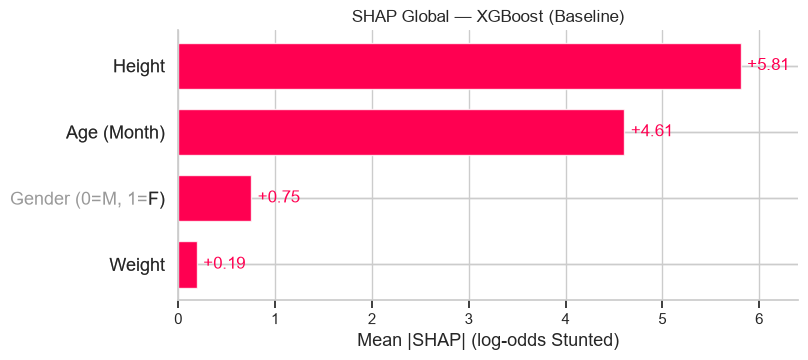

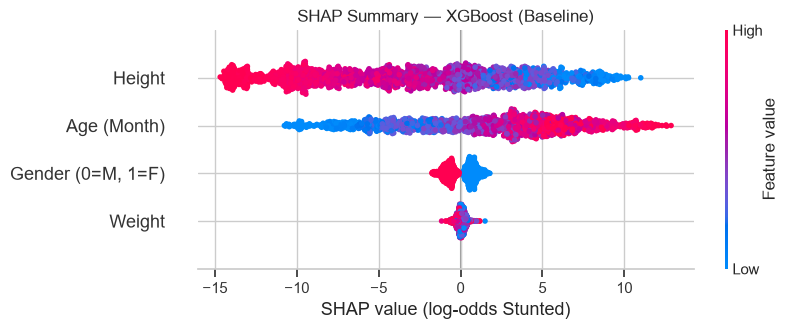

Global SHAP: LightGBM — Class Weight


,Feature,Mean Absolute SHAP
0,Height,5.328706
1,Age (Month),4.163229
2,Gender,0.593497
3,Weight,0.237321


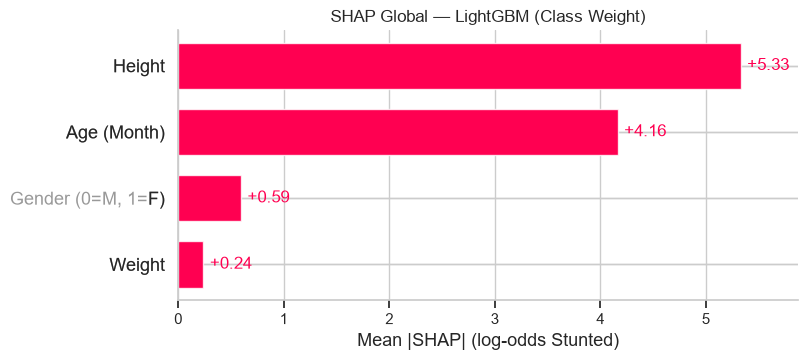

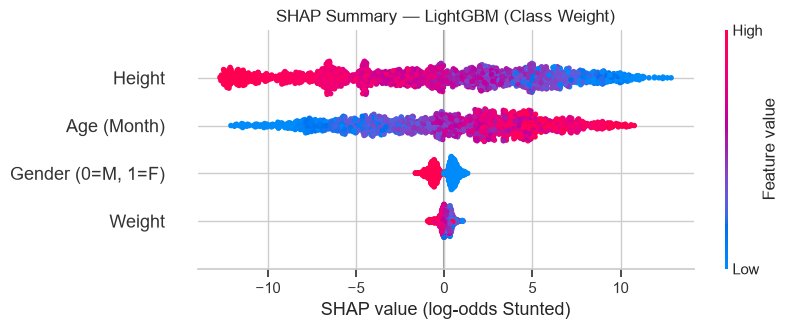

In [63]:
def shap_save_current(filename):
    plt.gcf().savefig(shap_output_dir / filename, dpi=200, bbox_inches="tight")
    plt.show()
    plt.close()

for shap_key, shap_explanation in shap_global.items():
    shap_algorithm, shap_method = shap_key
    shap_slug = shap_algorithm.lower()
    print("Global SHAP:", shap_algorithm, "—", shap_method)
    display(shap_importances[shap_key][["Feature", "Mean Absolute SHAP"]])
    shap_importances[shap_key].to_csv(shap_output_dir / f"shap_importance_{shap_slug}.csv", index=False)
    shap.plots.bar(shap_for_display(shap_explanation), max_display=len(FEATURES), show=False)
    plt.title(f"SHAP Global — {shap_algorithm} ({shap_method})")
    plt.xlabel("Mean |SHAP| (log-odds Stunted)")
    shap_save_current(f"shap_bar_{shap_slug}.png")
    shap.plots.beeswarm(shap_for_display(shap_explanation), max_display=len(FEATURES), show=False)
    plt.title(f"SHAP Summary — {shap_algorithm} ({shap_method})")
    plt.xlabel("SHAP value (log-odds Stunted)")
    shap_save_current(f"shap_beeswarm_{shap_slug}.png")

## 10.6 Feature Effect: Fitur Teratas, Height, dan Age (Month)
Plot menampilkan nilai fitur terhadap kontribusi SHAP pada pengamatan test. Fitur duplikat
hanya diplot sekali. Sebaran ini bukan eksperimen mengubah fitur dengan fitur lain tetap;
interaksi dan keterkaitan fitur dapat memengaruhi polanya. Karena itu grafik tidak membuktikan
pengaruh sebab-akibat. Gender, jika berada di ranking teratas, ditampilkan sebagai dua kategori.

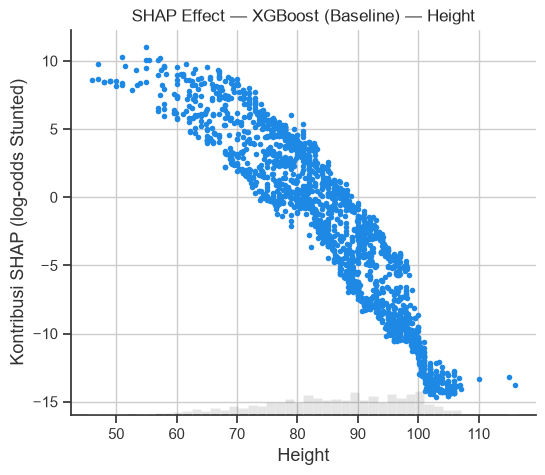

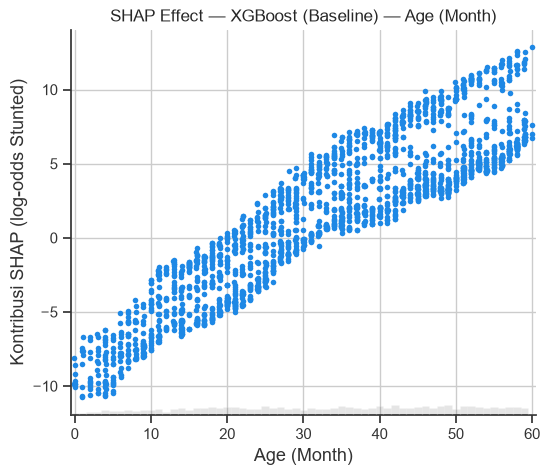

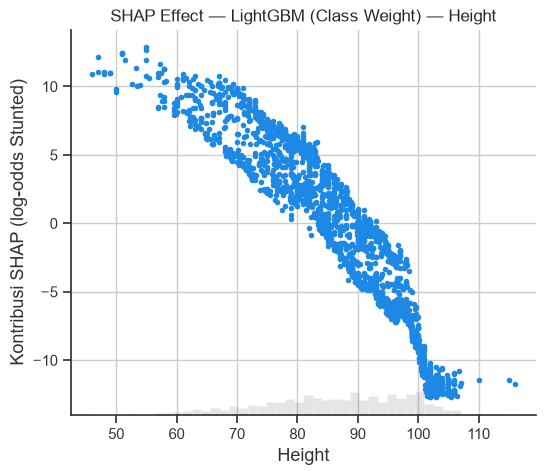

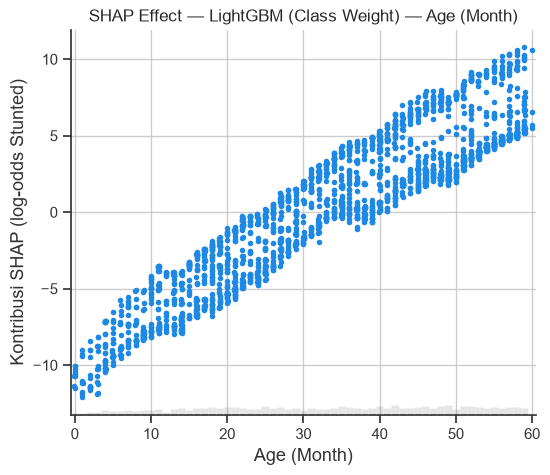

In [64]:
for shap_key, shap_explanation in shap_global.items():
    shap_algorithm, shap_method = shap_key
    shap_top_feature = shap_importances[shap_key].iloc[0]["Feature"]
    shap_effect_features = list(dict.fromkeys([shap_top_feature, "Height", "Age (Month)"]))
    for shap_feature in shap_effect_features:
        shap.plots.scatter(shap_explanation[:, shap_feature], show=False)
        plt.title(f"SHAP Effect — {shap_algorithm} ({shap_method}) — {shap_feature}")
        plt.ylabel("Kontribusi SHAP (log-odds Stunted)")
        if shap_feature == "Gender":
            plt.xticks([0, 1], ["M (laki-laki)", "F (perempuan)"])
            plt.xlabel("Jenis kelamin")
        shap_feature_slug = shap_feature.lower().replace(" ", "_").replace("(", "").replace(")", "")
        shap_save_current(f"shap_dependence_{shap_algorithm.lower()}_{shap_feature_slug}.png")

## 10.7 Interpretasi Lokal: True Positive dan False Negative
Untuk setiap model, ambil satu TP dan satu FN (jika ada) secara reproducible dari **seluruh
test**, berdasarkan pasangan label aktual dan prediksi tersimpan. Baris lokal boleh berada
di luar sampel global; jika demikian, SHAP dihitung langsung untuk baris itu tanpa fit ulang.
Contoh bersifat ilustratif, bukan ringkasan semua TP/FN atau bukti penyebab kesalahan.

Tabel menampilkan empat fitur, kelas aktual/prediksi, dan probabilitas Stunted. Waterfall
menguraikan raw margin dari nilai dasar menuju output individu. Nilai dasar bukan ambang
klasifikasi. Kontribusi positif tidak selalu berarti prediksi akhirnya Stunted: jumlah seluruh
kontribusi bersama nilai dasar yang menentukan output akhir.

XGBoost (Baseline) — TP — index test 7938


,Gender,Age (Month),Weight,Height,Gender meaning,Actual class,Predicted class,Predicted probability of Stunted
7938,0,48.0,11.2,87.1,M (laki-laki),Stunted,Stunted,0.999978


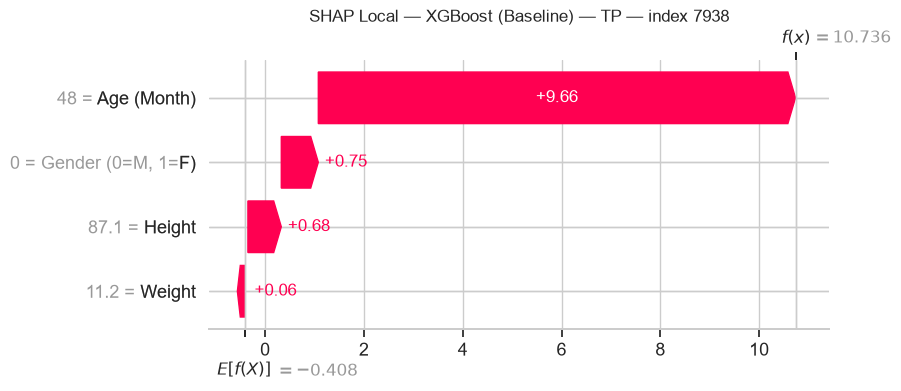

Kontribusi terbesar menuju Stunted: Age (Month) (+9.659981 log-odds).
XGBoost (Baseline) — FN — index test 5378


,Gender,Age (Month),Weight,Height,Gender meaning,Actual class,Predicted class,Predicted probability of Stunted
5378,0,0.0,3.3,50.3,M (laki-laki),Stunted,Not Stunted,0.062224


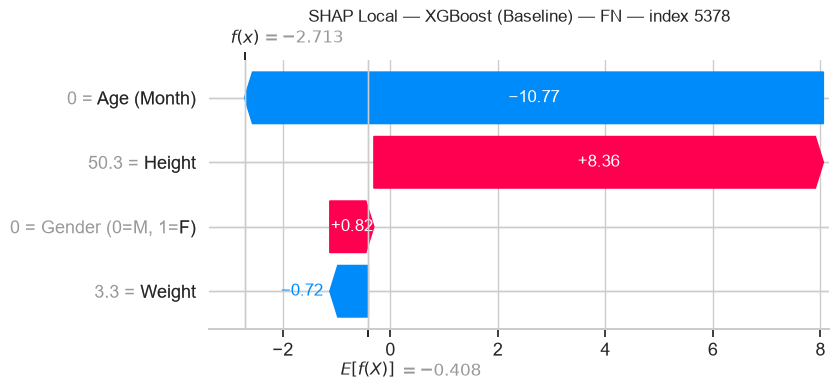

Kontribusi terbesar menuju Stunted: Height (+8.361221 log-odds).
Kontribusi terbesar menjauhi Stunted: Age (Month) (-10.767516 log-odds).
LightGBM (Class Weight) — TP — index test 11170


,Gender,Age (Month),Weight,Height,Gender meaning,Actual class,Predicted class,Predicted probability of Stunted
11170,1,11.0,6.7,61.5,F (perempuan),Stunted,Stunted,0.996861


c:\Users\m3500qc\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\shap\explainers\_tree.py:632: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


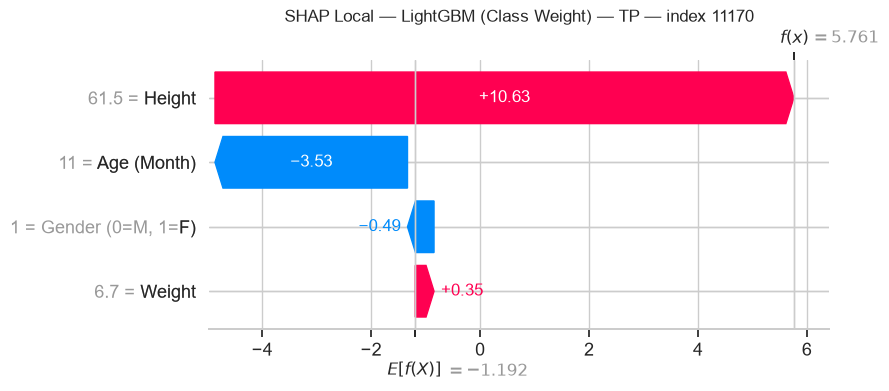

Kontribusi terbesar menuju Stunted: Height (+10.628157 log-odds).
Kontribusi terbesar menjauhi Stunted: Age (Month) (-3.534499 log-odds).
LightGBM (Class Weight) — FN — index test 9636


,Gender,Age (Month),Weight,Height,Gender meaning,Actual class,Predicted class,Predicted probability of Stunted
9636,0,20.0,9.5,79.0,M (laki-laki),Stunted,Not Stunted,0.416672


c:\Users\m3500qc\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\shap\explainers\_tree.py:632: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


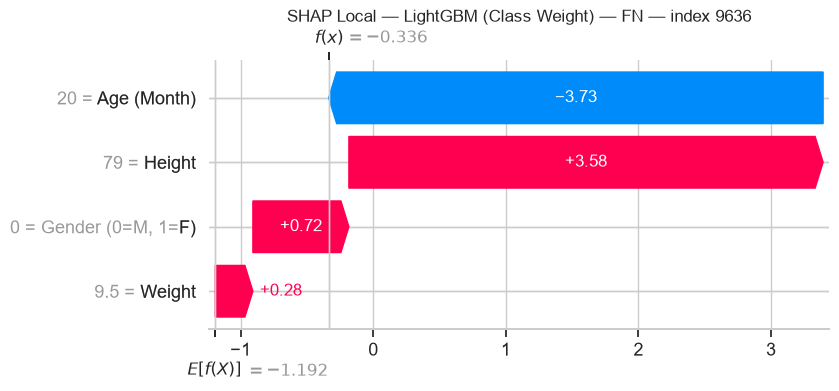

Kontribusi terbesar menuju Stunted: Height (+3.576415 log-odds).
Kontribusi terbesar menjauhi Stunted: Age (Month) (-3.728930 log-odds).


In [65]:
shap_local_records = []
for shap_key, shap_estimator in shap_models.items():
    shap_algorithm, shap_method = shap_key
    shap_pred_series = pd.Series(np.asarray(predictions[shap_key]), index=y_test.index)
    shap_proba_series = pd.Series(np.asarray(probabilities[shap_key]), index=y_test.index)
    shap_case_masks = {
        "TP": (y_test == 1) & (shap_pred_series == 1),
        "FN": (y_test == 1) & (shap_pred_series == 0)}
    for shap_case, shap_mask in shap_case_masks.items():
        if not shap_mask.any():
            print(f"{shap_algorithm} ({shap_method}): contoh {shap_case} tidak tersedia.")
            continue
        shap_local_frame = X_test.loc[shap_mask, FEATURES].sample(n=1, random_state=RANDOM_STATE).copy()
        shap_local_index = shap_local_frame.index[0]
        shap_sample_table = shap_local_frame.copy()
        shap_sample_table["Gender meaning"] = shap_sample_table["Gender"].map({0: "M (laki-laki)", 1: "F (perempuan)"})
        shap_sample_table["Actual class"] = y_test.loc[shap_local_frame.index].map({0: "Not Stunted", 1: "Stunted"})
        shap_sample_table["Predicted class"] = shap_pred_series.loc[shap_local_frame.index].map({0: "Not Stunted", 1: "Stunted"})
        shap_sample_table["Predicted probability of Stunted"] = shap_proba_series.loc[shap_local_frame.index]
        print(f"{shap_algorithm} ({shap_method}) — {shap_case} — index test {shap_local_index}")
        display(shap_sample_table)
        shap_local_explanation = shap_explain_frame(
            shap_explainers[shap_key], shap_estimator, shap_local_frame)
        shap.plots.waterfall(shap_for_display(shap_local_explanation)[0], max_display=len(FEATURES), show=False)
        plt.title(f"SHAP Local — {shap_algorithm} ({shap_method}) — {shap_case} — index {shap_local_index}")
        shap_save_current(f"shap_local_{shap_algorithm.lower()}_{shap_case.lower()}.png")
        shap_local_values = pd.Series(shap_local_explanation.values[0], index=FEATURES)
        for shap_direction, shap_contributions in [
                ("menuju Stunted", shap_local_values[shap_local_values > 0].sort_values(ascending=False)),
                ("menjauhi Stunted", shap_local_values[shap_local_values < 0].sort_values())]:
            if not shap_contributions.empty:
                print(f"Kontribusi terbesar {shap_direction}: {shap_contributions.index[0]} "
                      f"({shap_contributions.iloc[0]:+.6f} log-odds).")
        shap_local_records.append({
            "Model": shap_algorithm, "Imbalance Method": shap_method, "Case": shap_case,
            "Test index": shap_local_index, **shap_local_frame.iloc[0].to_dict(),
            "Actual class": int(y_test.loc[shap_local_index]),
            "Predicted class": int(shap_pred_series.loc[shap_local_index]),
            "Probability Stunted": float(shap_proba_series.loc[shap_local_index]),
            "Base value": float(shap_local_explanation.base_values[0]),
            **{f"SHAP {f}": float(shap_local_values[f]) for f in FEATURES}})
pd.DataFrame(shap_local_records).to_csv(shap_output_dir / "shap_local_examples.csv", index=False)

## 10.8 Ringkasan Otomatis dan Perbandingan XGBoost–LightGBM
Ringkasan dibuat dari SHAP aktual, termasuk kontribusi Weight dan Gender. Nilai kecil tidak
membuktikan bahwa fitur tidak relevan secara biologis: informasi dapat dibagi antarfitur yang
saling berkaitan. Mean absolute SHAP juga tidak menjelaskan arah efek; arah dilihat pada
beeswarm/dependence dan penjelasan individu.

Kedua model memakai unit log-odds dan sampel identik, tetapi memiliki fungsi prediksi,
nilai dasar, serta statistik lintasan training yang dapat berbeda akibat class weight/resampling.
Perbandingan lintas model terutama menilai **ranking**, bukan menyatakan angka SHAP salah satu
model lebih benar atau besarnya kontribusi kausal lebih kuat.

In [66]:
shap_summary_lines = []
for shap_key, shap_importance in shap_importances.items():
    shap_algorithm, shap_method = shap_key
    shap_top = shap_importance.iloc[0]
    shap_tied_top = shap_importance.loc[
        shap_importance["Mean Absolute SHAP"] == shap_top["Mean Absolute SHAP"], "Feature"].tolist()
    shap_summary_lines.extend([
        f"Interpretasi SHAP {shap_algorithm} ({shap_method}):",
        "- Fitur dengan kontribusi global terbesar: " + ", ".join(shap_tied_top) + ".",
        f"- Mean |SHAP| tertinggi: {shap_top['Mean Absolute SHAP']:.6f} log-odds.",
        "- Ranking aktual: " + " > ".join(shap_importance["Feature"]) + " (lihat Rank untuk nilai seri).",
        "- SHAP positif meningkatkan output menuju Stunted relatif terhadap nilai dasar; SHAP negatif menurunkannya."])
    for shap_feature in ["Weight", "Gender"]:
        shap_feature_row = shap_importance.set_index("Feature").loc[shap_feature]
        shap_summary_lines.append(
            f"- {shap_feature}: Mean |SHAP|={shap_feature_row['Mean Absolute SHAP']:.6f}, "
            f"rank={int(shap_feature_row['Rank'])}; ini kontribusi terhadap model, bukan bukti kausal/signifikansi.")

shap_comparison_parts = []
for shap_key, shap_importance in shap_importances.items():
    shap_algorithm = shap_key[0]
    shap_comparison_parts.append(shap_importance.set_index("Feature").rename(columns={
        "Mean Absolute SHAP": f"Mean |SHAP| {shap_algorithm}", "Rank": f"Rank {shap_algorithm}"}))
shap_comparison = pd.concat(shap_comparison_parts, axis=1).reindex(FEATURES).reset_index()
display(shap_comparison)
shap_same_ranks = bool((shap_comparison["Rank XGBoost"] == shap_comparison["Rank LightGBM"]).all())
shap_rank_agreement = shap_comparison["Rank XGBoost"].corr(shap_comparison["Rank LightGBM"], method="spearman")
shap_summary_lines.append(
    "Perbandingan: ranking kedua algoritma identik pada sampel ini." if shap_same_ranks else
    "Perbandingan: terdapat perbedaan ranking antaralgoritma pada sampel ini; lihat tabel per fitur.")
shap_summary_lines.append(
    f"Korelasi Spearman ranking empat fitur: {shap_rank_agreement:.6f}. "
    "Ini deskripsi kesesuaian ranking, bukan uji validitas atau signifikansi (NaN berarti ranking konstan).")
shap_summary_lines.append("Tidak ada interpretasi yang dinyatakan lebih benar berdasarkan perbandingan ini.")
print("\n".join(shap_summary_lines))
shap_comparison.to_csv(shap_output_dir / "shap_comparison.csv", index=False)
(shap_output_dir / "shap_interpretation.txt").write_text("\n".join(shap_summary_lines), encoding="utf-8")

,Feature,Mean |SHAP| XGBoost,Rank XGBoost,Mean |SHAP| LightGBM,Rank LightGBM
0,Gender,0.752685,3,0.593497,3
1,Age (Month),4.606399,2,4.163229,2
2,Weight,0.189998,4,0.237321,4
3,Height,5.807655,1,5.328706,1


Interpretasi SHAP XGBoost (Baseline):
- Fitur dengan kontribusi global terbesar: Height.
- Mean |SHAP| tertinggi: 5.807655 log-odds.
- Ranking aktual: Height > Age (Month) > Gender > Weight (lihat Rank untuk nilai seri).
- SHAP positif meningkatkan output menuju Stunted relatif terhadap nilai dasar; SHAP negatif menurunkannya.
- Weight: Mean |SHAP|=0.189998, rank=4; ini kontribusi terhadap model, bukan bukti kausal/signifikansi.
- Gender: Mean |SHAP|=0.752685, rank=3; ini kontribusi terhadap model, bukan bukti kausal/signifikansi.
Interpretasi SHAP LightGBM (Class Weight):
- Fitur dengan kontribusi global terbesar: Height.
- Mean |SHAP| tertinggi: 5.328706 log-odds.
- Ranking aktual: Height > Age (Month) > Gender > Weight (lihat Rank untuk nilai seri).
- SHAP positif meningkatkan output menuju Stunted relatif terhadap nilai dasar; SHAP negatif menurunkannya.
- Weight: Mean |SHAP|=0.237321, rank=4; ini kontribusi terhadap model, bukan bukti kausal/signifikansi.
- Gender: Mean |SHAP|=0.5

1374

## 10.9 Metadata, Validasi Akhir, dan Keterbatasan
Metadata mencatat model/metode terpilih, hyperparameter, versi library, seed, indeks sampel,
unit output, fingerprint model, dan contoh lokal. Hanya file berawalan `shap_` yang ditulis;
artefak eksperimen lama tidak ditimpa. Pemeriksaan akhir membandingkan results, seluruh
prediksi/probabilitas tersimpan, fingerprint delapan model, dan hash artefak lama.

**Catatan metodologis:** Karena status `Height for Age` secara antropometri dibentuk berdasarkan
usia, jenis kelamin, dan tinggi/panjang badan, dominasi fitur-fitur tersebut dalam SHAP merupakan
pola yang secara konseptual dapat diharapkan. SHAP dalam penelitian ini menjelaskan perilaku
model klasifikasi dan bukan menunjukkan hubungan sebab-akibat maupun faktor risiko longitudinal.
Dominasi aktual tetap harus dibaca dari hasil, bukan diasumsikan sebelumnya.

Fitur antropometri saling berkaitan; atribusi bergantung pada model serta asumsi penanganan
ketergantungan fitur. Tree-path-dependent menggunakan statistik pohon, yang dapat dipengaruhi
pembobotan/resampling training. Class weighting juga dapat memengaruhi kalibrasi probabilitas;
probabilitas yang ditampilkan adalah output model, bukan estimasi risiko klinis tervalidasi.
Sampling 2.000 baris dan contoh TP/FN tunggal tidak menggantikan analisis seluruh populasi atau
validasi eksternal. Pemilihan model dari F1 test dilakukan secara post-hoc untuk interpretasi;
grafik ini tidak boleh dipakai untuk tuning ulang lalu mengklaim test tetap independen.

**Batasan teknis:** output dengan layout SHAP yang tidak terdokumentasi akan ditolak, bukan
ditebak. Jika TreeExplainer tidak kompatibel dengan versi model, periksa versi dan format model;
tidak ada fallback yang melatih model pengganti atau mengabaikan kegagalan aditivitas.

In [67]:
assert_original_data()
pd.testing.assert_frame_equal(X_test, shap_X_test_snapshot, check_exact=True)
pd.testing.assert_series_equal(y_test, shap_y_test_snapshot, check_exact=True)
pd.testing.assert_frame_equal(results, shap_results_snapshot, check_exact=True)
assert set(predictions) == set(shap_predictions_snapshot)
assert set(probabilities) == set(shap_probabilities_snapshot)
assert set(searches) == set(shap_model_hashes_before)
for shap_key in searches:
    np.testing.assert_array_equal(predictions[shap_key], shap_predictions_snapshot[shap_key])
    np.testing.assert_array_equal(probabilities[shap_key], shap_probabilities_snapshot[shap_key])
    assert shap_model_fingerprint(shap_final_model(searches[shap_key].best_estimator_)) == shap_model_hashes_before[shap_key]
for shap_filename, shap_digest in shap_existing_artifact_hashes.items():
    assert hashlib.sha256((shap_output_dir / shap_filename).read_bytes()).hexdigest() == shap_digest
shap_metadata = {
    "status": "completed", "selection": "highest test F1 per algorithm, interpretation only",
    "tie_break": ["Recall descending", "ROC-AUC descending", "method name ascending"],
    "models": shap_selected[["Model", "Imbalance Method", "F1", "Recall", "ROC-AUC", "Best Hyperparameters"]].to_dict("records"),
    "features": FEATURES.copy(), "gender_encoding": {"0": "M", "1": "F"},
    "positive_class": 1, "sample_size": len(X_shap), "test_size": len(X_test),
    "random_state": RANDOM_STATE, "sample_test_indices": X_shap.index.tolist(),
    "local_examples": [{"model": r["Model"], "method": r["Imbalance Method"],
                        "case": r["Case"], "test_index": r["Test index"]} for r in shap_local_records],
    "model_output": "raw log-odds of Stunted", "feature_perturbation": "tree_path_dependent",
    "packages": {name: version(name) for name in ["shap", "xgboost", "lightgbm", "numpy", "pandas", "scikit-learn"]},
    "model_sha256": {" — ".join(key): digest for key, digest in shap_model_hashes_before.items()},
    "sample_sha256": hashlib.sha256(pd.util.hash_pandas_object(X_shap, index=True).values.tobytes()).hexdigest(),
    "original_artifact_sha256": shap_existing_artifact_hashes,
    "integrity_checks": "passed: test, results, predictions, probabilities, 8 models, original artifacts",
    "additivity_checks": "passed: raw margin and positive-class probability",
    "training_or_resampling_performed": False}
(shap_output_dir / "shap_metadata.json").write_text(
    json.dumps(shap_metadata, ensure_ascii=False, indent=2, default=str), encoding="utf-8")
print("Analisis SHAP selesai. Test, hasil 8 eksperimen, model, dan artefak lama tetap identik.")
print("Artefak SHAP:", shap_output_dir)

Analisis SHAP selesai. Test, hasil 8 eksperimen, model, dan artefak lama tetap identik.
Artefak SHAP: d:\Kuliah\Semester9\Notebook\results\master_v2
